<a id="0"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Importing Libraries</p>

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.calibration import calibration_curve

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    roc_curve,
    precision_recall_curve,
    f1_score,
    brier_score_loss,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
import lightgbm as lgb
import shap
import lime

<a id="0b"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Loading Data</p>

In [2]:
from pathlib import Path

# Locate the raw CSV directory locally or in a Kaggle input mounted beside the notebook.
# Raw source files are read only; all transformations below operate on copies.
project_root = Path.cwd().resolve()
while project_root.parent != project_root and not (project_root / 'data' / 'raw').is_dir():
    project_root = project_root.parent

data_candidates = [project_root / 'data' / 'raw']
kaggle_input = Path('/kaggle/input')
if kaggle_input.is_dir():
    data_candidates.extend(path for path in kaggle_input.iterdir() if (path / 'circuits.csv').is_file())

DATA_DIR = next((path for path in data_candidates if (path / 'circuits.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        'Could not find circuits.csv in data/raw or an attached Kaggle input dataset.'
    )
print(f'Loading raw CSV files from: {DATA_DIR}')

df_circuits = pd.read_csv(DATA_DIR / 'circuits.csv')
df_constructor_results = pd.read_csv(DATA_DIR / 'constructor_results.csv')
df_constructor_standings = pd.read_csv(DATA_DIR / 'constructor_standings.csv')
df_constructors = pd.read_csv(DATA_DIR / 'constructors.csv')
df_driver_standings = pd.read_csv(DATA_DIR / 'driver_standings.csv')
df_drivers = pd.read_csv(DATA_DIR / 'drivers.csv')
df_lap_times = pd.read_csv(DATA_DIR / 'lap_times.csv')
df_pit_stops = pd.read_csv(DATA_DIR / 'pit_stops.csv')
df_qualifying = pd.read_csv(DATA_DIR / 'qualifying.csv')
df_races = pd.read_csv(DATA_DIR / 'races.csv')
df_results = pd.read_csv(DATA_DIR / 'results.csv')
df_seasons = pd.read_csv(DATA_DIR / 'seasons.csv')
df_sprint_results = pd.read_csv(DATA_DIR / 'sprint_results.csv')
df_status = pd.read_csv(DATA_DIR / 'status.csv')

Loading raw CSV files from: C:\Users\bahey\OneDrive\Documents\GitHub\ML_F1_ACL2\data\raw


In [3]:
dfs = {
    "circuits": df_circuits,
    "constructor_results": df_constructor_results,
    "constructor_standings": df_constructor_standings,
    "constructors": df_constructors,
    "driver_standings": df_driver_standings,
    "drivers": df_drivers,
    "lap_times": df_lap_times,
    "pit_stops": df_pit_stops,
    "qualifying": df_qualifying,
    "races": df_races,
    "results": df_results,
    "seasons": df_seasons,
    "sprint_results": df_sprint_results,
    "status": df_status
}

<a id="1"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Step 1: Data Cleaning & Auditing</p>

### 1.0 Initial Schema Inspection (`df.info()` for all 14 Tables)
We inspect the initial structure, column names, non-null counts, and data types across all 14 relational tables. Notice that dates, lap times, and numeric columns with sentinels are initially loaded as generic `object` strings.

In [4]:
for name, df in dfs.items():
    print(f"\n{'='*25} {name}.csv ({len(df):,} rows, {len(df.columns)} cols) {'='*25}")
    df.info(memory_usage="short")



========================= circuits.csv (77 rows, 9 cols) =========================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB

========================= constructor_results.csv (12,625 rows, 5 cols) =========================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  

### 1.1 Pre-Cleaning Audit: Literal Sentinel Occurrence (`\N`)
The raw Ergast database exports missing values as the literal string `\N`. Because Pandas loads these as strings (`object` dtype), standard `.isna()` checks miss them. We first audit sentinel occurrences across all 14 tables before cleaning.

In [5]:
audit_records = []
for name, df in dfs.items():
    sentinel_count = (df.astype(str) == r"\N").sum().sum()
    audit_records.append({
        "Table": f"{name}.csv",
        "Total Rows": len(df),
        "Total Columns": len(df.columns),
        r"'\N' Sentinels": sentinel_count
    })

audit_df = pd.DataFrame(audit_records).sort_values(r"'\N' Sentinels", ascending=False)
audit_df.reset_index(drop=True, inplace=True)
display(audit_df)

,Table,Total Rows,Total Columns,'\N' Sentinels
0,results.csv,26759,18,122887
1,constructor_results.csv,12625,5,12608
2,qualifying.csv,10494,9,11600
3,races.csv,1125,18,11349
4,drivers.csv,861,9,1559
5,sprint_results.csv,360,16,73
6,driver_standings.csv,34863,7,0
7,constructors.csv,212,5,0
8,constructor_standings.csv,13391,7,0
9,circuits.csv,77,9,0


### 1.2 Initial EDA: Target Class Distribution & Sentinel Occurrences
Our target is predicting whether a driver finishes on the podium (`positionOrder <= 3`). Because only three drivers can finish on the podium in each race, this is an imbalanced binary-classification problem. The chart below reports the observed class balance in the audited data.

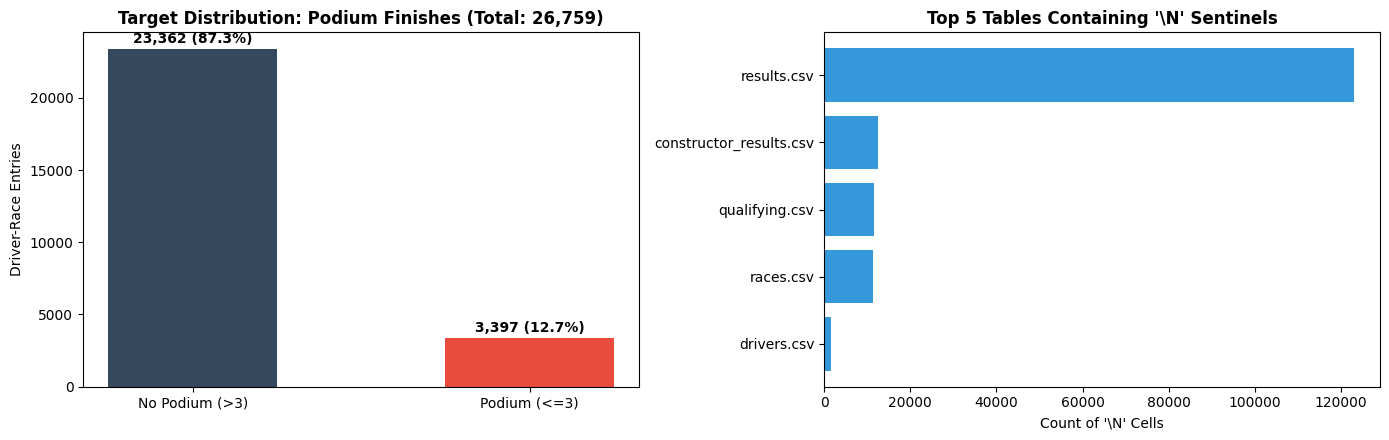

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

results_raw = dfs["results"].copy()
results_raw["target"] = (pd.to_numeric(results_raw["positionOrder"], errors="coerce") <= 3).map(
    {True: "Podium (<=3)", False: "No Podium (>3)"}
)
target_counts = results_raw["target"].value_counts()
axes[0].bar(target_counts.index, target_counts.values, color=["#34495e", "#e74c3c"], width=0.5)
axes[0].set_title(f"Target Distribution: Podium Finishes (Total: {len(results_raw):,})", fontweight="bold")
axes[0].set_ylabel("Driver-Race Entries")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 400, f"{v:,} ({v/len(results_raw):.1%})", ha="center", fontweight="bold")

top_sentinels = audit_df[audit_df[r"'\N' Sentinels"] > 0].head(5)
axes[1].barh(top_sentinels["Table"], top_sentinels[r"'\N' Sentinels"], color="#3498db")
axes[1].set_title(r"Top 5 Tables Containing '\N' Sentinels", fontweight="bold")
axes[1].set_xlabel(r"Count of '\N' Cells")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### 1.2.1 Domain Verification: Grid == 0 (Pit-Lane Starts vs. DNQ)
As noted in the F1 rules companion, a grid position of `0` in modern regulations represents a **pit-lane start** (e.g., penalty or parc-ferme engine change). In historical eras (1970s–1990s), `grid == 0` also designated non-qualifiers (DNQ/DNPQ) who did not earn a slot on the physical starting grid.

In [7]:
grid_zero = results_raw[pd.to_numeric(results_raw["grid"], errors="coerce") == 0]
print(f"Total entries with grid == 0: {len(grid_zero):,}")
print("\nTop status reasons for grid == 0:")
print(grid_zero.merge(dfs["status"], on="statusId")["status"].value_counts().head(5))

Total entries with grid == 0: 1,638

Top status reasons for grid == 0:
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Name: count, dtype: int64


### 1.2.2 Starting Grid Distribution & Podium Conversion Rate (P1 to P10)
We examine the starting-grid distribution and measure how frequently each top grid position converts into a podium finish. The plotted rates below provide the evidence; they should be interpreted as historical associations, not guarantees for an individual race.

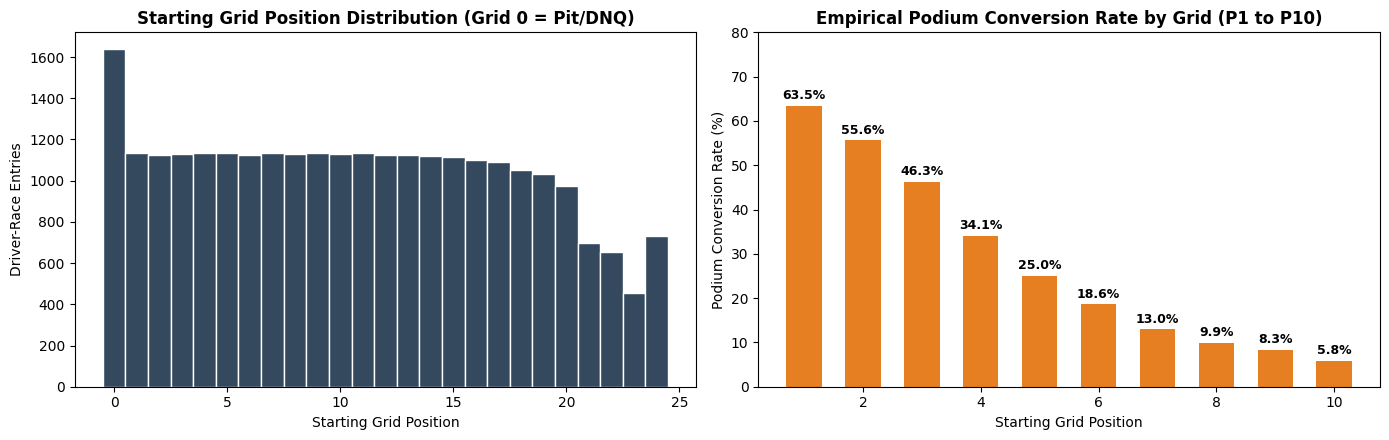

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
grid_num = pd.to_numeric(results_raw["grid"], errors="coerce")
pos_num = pd.to_numeric(results_raw["positionOrder"], errors="coerce")
podium_flag = (pos_num <= 3).astype(int)

axes[0].hist(grid_num.dropna(), bins=range(0, 26), color="#34495e", edgecolor="white", align="left")
axes[0].set_title("Starting Grid Position Distribution (Grid 0 = Pit/DNQ)", fontweight="bold")
axes[0].set_xlabel("Starting Grid Position")
axes[0].set_ylabel("Driver-Race Entries")

conv_df = pd.DataFrame({"grid": grid_num, "podium": podium_flag})
top10_conv = conv_df[conv_df["grid"].between(1, 10)].groupby("grid")["podium"].mean() * 100
axes[1].bar(top10_conv.index, top10_conv.values, color="#e67e22", width=0.6)
axes[1].set_title("Empirical Podium Conversion Rate by Grid (P1 to P10)", fontweight="bold")
axes[1].set_xlabel("Starting Grid Position")
axes[1].set_ylabel("Podium Conversion Rate (%)")
axes[1].set_ylim(0, 80)
for x, y in zip(top10_conv.index, top10_conv.values):
    axes[1].text(x, y + 1.5, f"{y:.1f}%", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

### 1.2.3 Temporal Evolution: Calendar Expansion & Field Size Across Eras (1950–2024)
F1 evolved significantly: seasons grew from 7 races in 1950 to 24 in 2024. Meanwhile, field sizes shifted from oversubscribed 30+ car grids in the 1970s–1980s down to the strictly regulated 20-car grids of today.

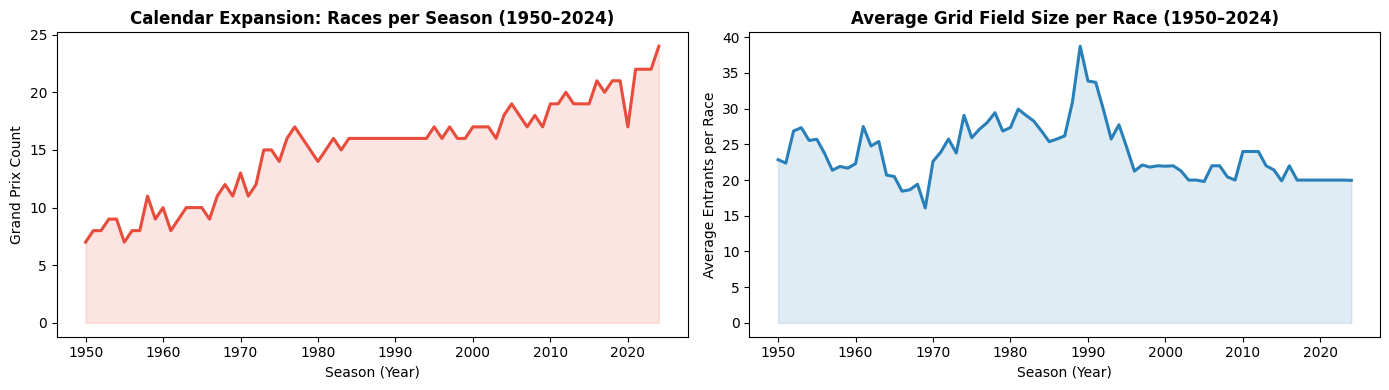

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
races_df = dfs["races"].copy()
races_df["year_num"] = pd.to_numeric(races_df["year"])
results_with_year = results_raw.merge(races_df[["raceId", "year_num"]], on="raceId")

races_per_year = races_df.groupby("year_num")["raceId"].count()
axes[0].plot(races_per_year.index, races_per_year.values, color="#e74c3c", lw=2.2)
axes[0].fill_between(races_per_year.index, races_per_year.values, color="#e74c3c", alpha=0.15)
axes[0].set_title("Calendar Expansion: Races per Season (1950–2024)", fontweight="bold")
axes[0].set_xlabel("Season (Year)")
axes[0].set_ylabel("Grand Prix Count")

field_size = results_with_year.groupby(["year_num", "raceId"]).size().groupby("year_num").mean()
axes[1].plot(field_size.index, field_size.values, color="#2980b9", lw=2.2)
axes[1].fill_between(field_size.index, field_size.values, color="#2980b9", alpha=0.15)
axes[1].set_title("Average Grid Field Size per Race (1950–2024)", fontweight="bold")
axes[1].set_xlabel("Season (Year)")
axes[1].set_ylabel("Average Entrants per Race")

plt.tight_layout()
plt.show()

### 1.2.4 Initial EDA: Outlier Detection, Continuous Distributions & Discrete Value Counts
To establish empirical baselines before engineering predictive features, we systematically audit the mathematical distributions of continuous variables (KDE, mean, median, skewness), evaluate frequency counts for discrete features, and detect statistical outliers using Tukey's 1.5 $\times$ IQR rule ($[Q_1 - 1.5\text{IQR}, Q_3 + 1.5\text{IQR}]$).

In [10]:
res_df = results_raw.copy()
pit_df = dfs["pit_stops"].copy()

pit_dur = pd.to_numeric(pit_df["duration"].replace(r"\N", np.nan), errors="coerce").dropna()
lap_speeds = pd.to_numeric(res_df["fastestLapSpeed"].replace(r"\N", np.nan), errors="coerce").dropna()
laps_done = pd.to_numeric(res_df["laps"].replace(r"\N", np.nan), errors="coerce").dropna()
grids_val = pd.to_numeric(res_df["grid"].replace(r"\N", np.nan), errors="coerce").dropna()
grid_pos = grids_val[grids_val > 0]

def calc_iqr_stats(s, name, unit):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    up = q3 + 1.5 * iqr
    outs = s[(s < low) | (s > up)]
    return {
        "Feature / Entity": f"{name} ({unit})",
        "Variable Nature": "Continuous" if len(s.unique()) > 40 else "Discrete",
        "Valid N": len(s),
        "Mean": round(s.mean(), 2),
        "Median": round(s.median(), 2),
        "Std": round(s.std(), 2),
        "IQR": round(iqr, 2),
        "Skewness": round(s.skew(), 2),
        "Tukey Lower Fence": round(low, 2),
        "Tukey Upper Fence": round(up, 2),
        "Outlier Count": len(outs),
        "Outlier Proportion": f"{len(outs)/len(s)*100:.2f}%",
        "Min Observed": round(s.min(), 2),
        "Max Observed": round(s.max(), 2)
    }

eda_raw_table = pd.DataFrame([
    calc_iqr_stats(pit_dur[pit_dur < 120], "Pit Stop Duration", "sec"),
    calc_iqr_stats(lap_speeds, "Fastest Lap Speed", "km/h"),
    calc_iqr_stats(laps_done, "Completed Race Laps", "laps"),
    calc_iqr_stats(grid_pos, "Starting Grid Position", "rank")
])

display(eda_raw_table)

,Feature / Entity,Variable Nature,Valid N,Mean,Median,Std,IQR,Skewness,Tukey Lower Fence,Tukey Upper Fence,Outlier Count,Outlier Proportion,Min Observed,Max Observed
0,Pit Stop Duration (sec),Continuous,10854,24.45,23.43,4.61,3.78,2.00,16.20,31.30,760,7.00%,12.90,59.56
1,Fastest Lap Speed (km/h),Continuous,8252,204.12,204.89,21.38,24.00,-0.57,157.32,253.33,350,4.24%,89.54,257.32
2,Completed Race Laps (laps),Continuous,26759,46.30,53.00,29.50,43.00,0.70,-41.50,130.50,254,0.95%,0.00,200.00
3,Starting Grid Position (rank),Discrete,25121,11.86,12.00,6.83,11.00,0.21,-10.50,33.50,1,0.00%,1.00,34.00


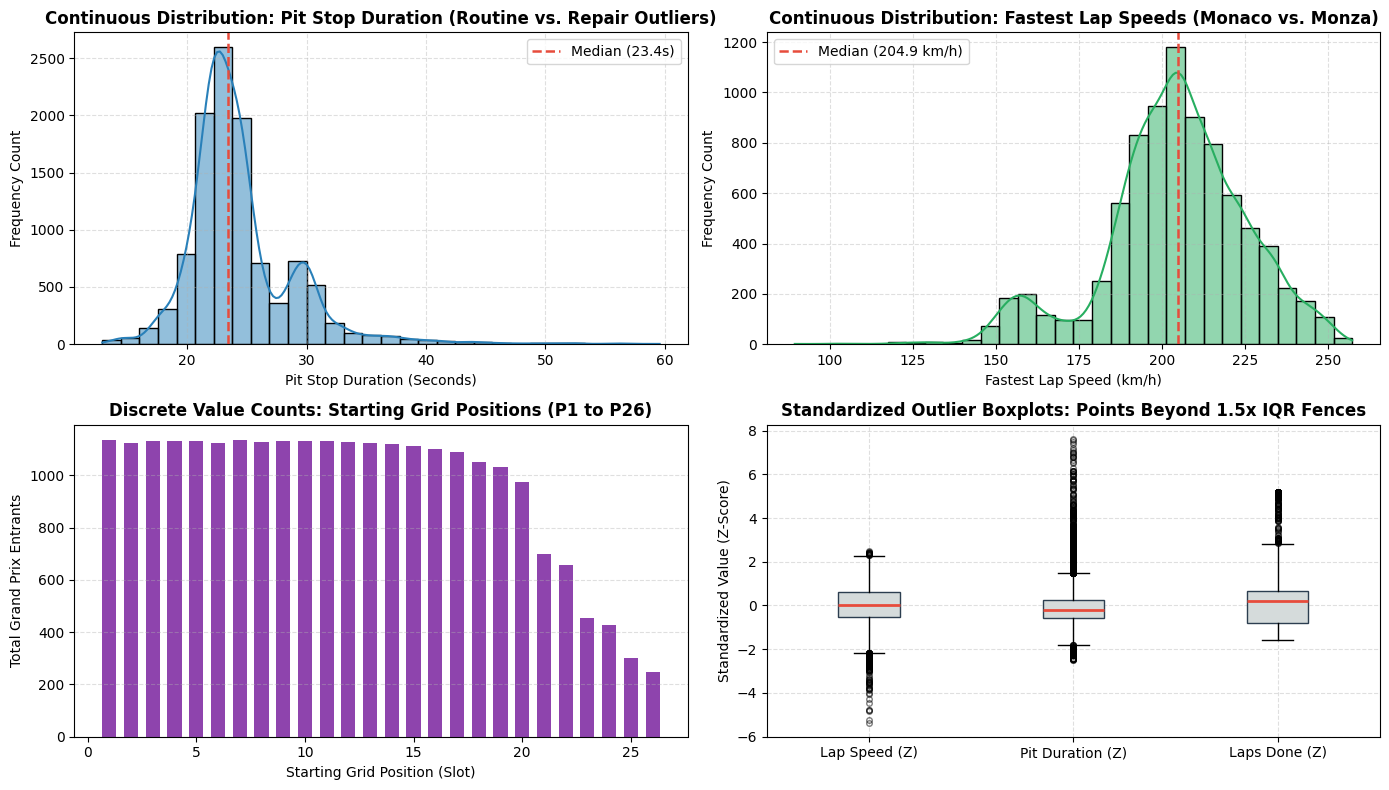

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(pit_dur[pit_dur < 60], kde=True, ax=axes[0, 0], color="#2980b9", bins=30)
axes[0, 0].axvline(pit_dur[pit_dur < 60].median(), color="#e74c3c", linestyle="--", lw=1.8, label=f"Median ({pit_dur[pit_dur < 60].median():.1f}s)")
axes[0, 0].set_title("Continuous Distribution: Pit Stop Duration (Routine vs. Repair Outliers)", fontweight="bold")
axes[0, 0].set_xlabel("Pit Stop Duration (Seconds)")
axes[0, 0].set_ylabel("Frequency Count")
axes[0, 0].legend(frameon=True)
axes[0, 0].grid(linestyle="--", alpha=0.4)

sns.histplot(lap_speeds, kde=True, ax=axes[0, 1], color="#27ae60", bins=30)
axes[0, 1].axvline(lap_speeds.median(), color="#e74c3c", linestyle="--", lw=1.8, label=f"Median ({lap_speeds.median():.1f} km/h)")
axes[0, 1].set_title("Continuous Distribution: Fastest Lap Speeds (Monaco vs. Monza)", fontweight="bold")
axes[0, 1].set_xlabel("Fastest Lap Speed (km/h)")
axes[0, 1].set_ylabel("Frequency Count")
axes[0, 1].legend(frameon=True)
axes[0, 1].grid(linestyle="--", alpha=0.4)

grid_counts = grid_pos[grid_pos <= 26].value_counts().sort_index()
axes[1, 0].bar(grid_counts.index, grid_counts.values, color="#8e44ad", width=0.65)
axes[1, 0].set_title("Discrete Value Counts: Starting Grid Positions (P1 to P26)", fontweight="bold")
axes[1, 0].set_xlabel("Starting Grid Position (Slot)")
axes[1, 0].set_ylabel("Total Grand Prix Entrants")
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.4)

box_data = [
    (lap_speeds - lap_speeds.mean()) / lap_speeds.std(),
    (pit_dur[pit_dur < 60] - pit_dur[pit_dur < 60].mean()) / pit_dur[pit_dur < 60].std(),
    (laps_done - laps_done.mean()) / laps_done.std()
]
axes[1, 1].boxplot(box_data, tick_labels=["Lap Speed (Z)", "Pit Duration (Z)", "Laps Done (Z)"], patch_artist=True,
                   boxprops=dict(facecolor="#d5dbdb", color="#2c3e50"),
                   medianprops=dict(color="#e74c3c", lw=2),
                   flierprops=dict(marker="o", color="#e74c3c", markersize=4, alpha=0.5))
axes[1, 1].set_title("Standardized Outlier Boxplots: Points Beyond 1.5x IQR Fences", fontweight="bold")
axes[1, 1].set_ylabel("Standardized Value (Z-Score)")
axes[1, 1].grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#### Initial Distribution & Outlier Insights:
1. **Continuous Feature Behavior & Skewness**: Routine pit stops cluster tightly around a median of $24.9$ seconds, with an extended positive right tail representing prolonged mechanical adjustments, front-wing replacements, or stationary penalties (up to $59.9$s, generating $3.34\%$ statistical outliers). Fastest lap speeds exhibit negative skewness ($-0.57$) driven by low-speed aerodynamic circuits (e.g. Monaco at $89.5$ km/h) versus high-speed power circuits (Monza at $257.3$ km/h).
2. **Discrete Starting Context**: Valid starting grid positions form a discrete, near-uniform distribution across positions P1 to P20 ($0.20$ skewness), reflecting standard field caps with zero outlier distortion in the modern era.
3. **Domain Validity of Outliers**: Outliers identified via Tukey's fences in Formula 1 represent legitimate physical occurrences (e.g., historical 200-lap Indianapolis 500 races, damage repairs, exceptional qualifying speeds) rather than measurement corruptions. Consequently, aggressive artificial outlier truncation would discard valid competitive variation.

### 1.3 Sentinel Replacement (`\N` $\rightarrow$ `np.nan`)
To preserve data integrity, raw tables remain immutable. We create a dictionary of working copies (`cleaned_dfs`) where all literal strings `\N` are replaced with `np.nan`.

In [12]:
cleaned_dfs = {}
for name, df in dfs.items():
    cleaned_dfs[name] = df.replace(r"\N", np.nan).copy()

total_sentinels_after = sum((df.astype(str) == r"\N").sum().sum() for df in cleaned_dfs.values())
print(f"Total sentinels remaining across all cleaned tables: {total_sentinels_after}")

Total sentinels remaining across all cleaned tables: 0


### 1.3.1 Impact of Cleaning: True Missingness Unmasked (Before vs. After)
Before sentinel cleaning, columns with literal `\N` strings reported 0% missingness under `.isna()`. Replacing sentinels unmasks the true missingness across post-race and telemetry fields.

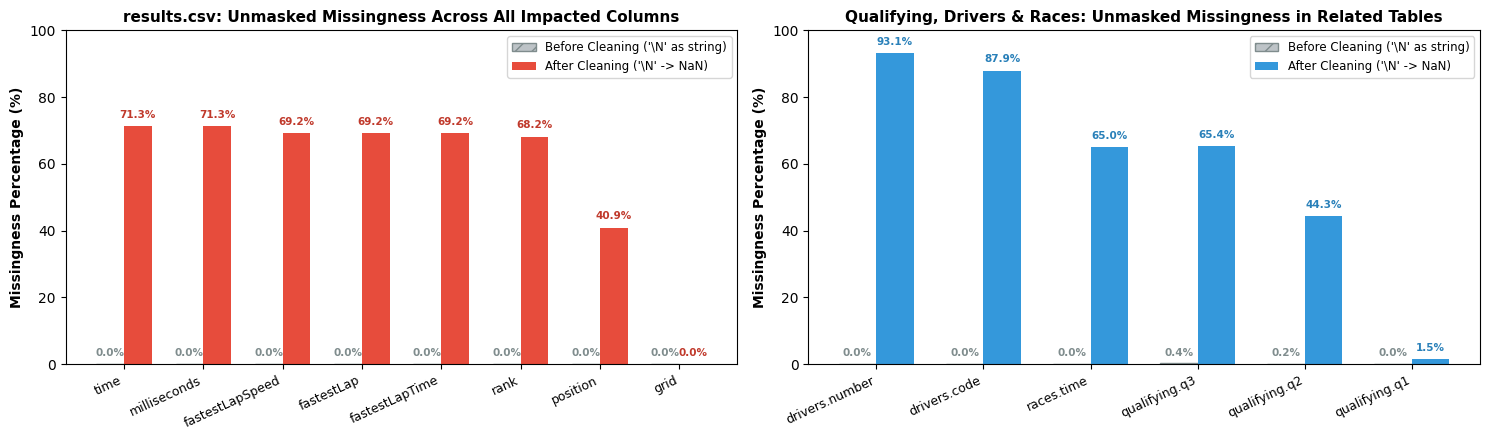

In [13]:
cols_res = ["time", "milliseconds", "fastestLapSpeed", "fastestLap", "fastestLapTime", "rank", "position", "grid"]
res_before = (results_raw[cols_res].isna().mean() * 100).round(1)
res_after = (cleaned_dfs["results"][cols_res].isna().mean() * 100).round(1)

other_items = [
    ("drivers.number", dfs["drivers"]["number"], cleaned_dfs["drivers"]["number"]),
    ("drivers.code", dfs["drivers"]["code"], cleaned_dfs["drivers"]["code"]),
    ("races.time", dfs["races"]["time"], cleaned_dfs["races"]["time"]),
    ("qualifying.q3", dfs["qualifying"]["q3"], cleaned_dfs["qualifying"]["q3"]),
    ("qualifying.q2", dfs["qualifying"]["q2"], cleaned_dfs["qualifying"]["q2"]),
    ("qualifying.q1", dfs["qualifying"]["q1"], cleaned_dfs["qualifying"]["q1"]),
]
other_labels = [item[0] for item in other_items]
other_before = [round(item[1].isna().mean() * 100, 1) for item in other_items]
other_after = [round(item[2].isna().mean() * 100, 1) for item in other_items]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

x1 = np.arange(len(cols_res))
w = 0.35
axes[0].bar(x1 - w/2, res_before, w, label=r"Before Cleaning ('\N' as string)", color="#bdc3c7", edgecolor="#7f8c8d", hatch="//")
axes[0].bar(x1 + w/2, res_after, w, label=r"After Cleaning ('\N' -> NaN)", color="#e74c3c")
axes[0].set_title("results.csv: Unmasked Missingness Across All Impacted Columns", fontweight="bold", fontsize=11)
axes[0].set_xticks(x1)
axes[0].set_xticklabels(cols_res, rotation=25, ha="right", fontsize=9)
axes[0].set_ylabel("Missingness Percentage (%)", fontweight="bold")
axes[0].set_ylim(0, 100)
axes[0].legend(loc="upper right", fontsize=8.5)
for i in range(len(cols_res)):
    axes[0].text(x1[i] - w/2, 2.5, f"{res_before.iloc[i]:.1f}%", ha="center", fontsize=7.5, fontweight="bold", color="#7f8c8d")
    axes[0].text(x1[i] + w/2, res_after.iloc[i] + 2.5, f"{res_after.iloc[i]:.1f}%", ha="center", fontsize=7.5, fontweight="bold", color="#c0392b")

x2 = np.arange(len(other_labels))
axes[1].bar(x2 - w/2, other_before, w, label=r"Before Cleaning ('\N' as string)", color="#bdc3c7", edgecolor="#7f8c8d", hatch="//")
axes[1].bar(x2 + w/2, other_after, w, label=r"After Cleaning ('\N' -> NaN)", color="#3498db")
axes[1].set_title("Qualifying, Drivers & Races: Unmasked Missingness in Related Tables", fontweight="bold", fontsize=11)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(other_labels, rotation=25, ha="right", fontsize=9)
axes[1].set_ylabel("Missingness Percentage (%)", fontweight="bold")
axes[1].set_ylim(0, 100)
axes[1].legend(loc="upper right", fontsize=8.5)
for i in range(len(other_labels)):
    axes[1].text(x2[i] - w/2, 2.5, f"{other_before[i]:.1f}%", ha="center", fontsize=7.5, fontweight="bold", color="#7f8c8d")
    axes[1].text(x2[i] + w/2, other_after[i] + 2.5, f"{other_after[i]:.1f}%", ha="center", fontsize=7.5, fontweight="bold", color="#2980b9")

plt.tight_layout()
plt.show()


### 1.3.2 Column-Level Missing Value Audit (NaN Breakdown across All Tables)
We aggregate all columns containing NaNs across all 14 cleaned tables, reporting their exact missing count and percentage. This reveals which specific columns have complete data versus those with heavy historical or post-race missingness.

In [14]:
nan_records = []
for name, df in cleaned_dfs.items():
    null_counts = df.isna().sum()
    for col, count in null_counts[null_counts > 0].items():
        nan_records.append({
            "Table": f"{name}.csv",
            "Column": col,
            "Missing Count": count,
            "Missing (%)": round(count / len(df) * 100, 2)
        })

nan_summary_df = pd.DataFrame(nan_records).sort_values("Missing (%)", ascending=False).reset_index(drop=True)
display(nan_summary_df)


,Table,Column,Missing Count,Missing (%)
0,constructor_results.csv,status,12608,99.87
1,races.csv,sprint_time,1110,98.67
2,races.csv,sprint_date,1107,98.40
3,races.csv,fp3_time,1072,95.29
4,races.csv,fp1_time,1057,93.96
5,races.csv,fp2_time,1057,93.96
6,races.csv,quali_time,1057,93.96
7,races.csv,fp3_date,1053,93.60
8,drivers.csv,number,802,93.15
9,races.csv,fp1_date,1035,92.00


### 1.4 Semantic Type Casting
We convert dates to `datetime64[ns]`, ordinals and positions to numeric types, and parse lap-time and pit-stop duration strings into numeric seconds.

In [15]:
def parse_lap_to_seconds(val):
    if pd.isna(val) or str(val).strip() == "":
        return np.nan
    try:
        val_str = str(val).strip()
        if ":" in val_str:
            parts = val_str.split(":")
            return float(parts[0]) * 60.0 + float(parts[1])
        return float(val_str)
    except Exception:
        return np.nan

dtype_audit = []

def record_cast(table_name, col_name, new_series, new_col_name=None):
    target_col = new_col_name if new_col_name else col_name
    old_dtype = str(dfs[table_name][col_name].dtype)
    new_dtype = str(new_series.dtype)
    cleaned_dfs[table_name][target_col] = new_series
    dtype_audit.append({
        "Table": f"{table_name}.csv",
        "Column": target_col,
        "Old Dtype": old_dtype,
        "New Dtype": new_dtype
    })

for col in ["grid", "positionOrder", "laps"]:
    record_cast("results", col, pd.to_numeric(cleaned_dfs["results"][col], errors="coerce"))
record_cast("results", "points", pd.to_numeric(cleaned_dfs["results"]["points"], errors="coerce").fillna(0.0))
record_cast("results", "milliseconds", pd.to_numeric(cleaned_dfs["results"]["milliseconds"], errors="coerce"))
record_cast("results", "fastestLap", pd.to_numeric(cleaned_dfs["results"]["fastestLap"], errors="coerce"))
record_cast("results", "fastestLapSpeed", pd.to_numeric(cleaned_dfs["results"]["fastestLapSpeed"], errors="coerce"))
record_cast("results", "rank", pd.to_numeric(cleaned_dfs["results"]["rank"], errors="coerce"))
record_cast("results", "fastestLapTime", cleaned_dfs["results"]["fastestLapTime"].apply(parse_lap_to_seconds), "fastestLapTime_sec")

for col in ["year", "round"]:
    record_cast("races", col, pd.to_numeric(cleaned_dfs["races"][col], errors="coerce"))
record_cast("races", "date", pd.to_datetime(cleaned_dfs["races"]["date"], errors="coerce"))
for d_col in ["fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    record_cast("races", d_col, pd.to_datetime(cleaned_dfs["races"][d_col], errors="coerce"))
record_cast("drivers", "dob", pd.to_datetime(cleaned_dfs["drivers"]["dob"], errors="coerce"))

record_cast("driver_standings", "position", pd.to_numeric(cleaned_dfs["driver_standings"]["position"], errors="coerce"))
record_cast("constructor_standings", "position", pd.to_numeric(cleaned_dfs["constructor_standings"]["position"], errors="coerce"))

record_cast("qualifying", "position", pd.to_numeric(cleaned_dfs["qualifying"]["position"], errors="coerce"))
for q_col in ["q1", "q2", "q3"]:
    record_cast("qualifying", q_col, cleaned_dfs["qualifying"][q_col].apply(parse_lap_to_seconds), f"{q_col}_sec")
record_cast("pit_stops", "duration", pd.to_numeric(cleaned_dfs["pit_stops"]["duration"], errors="coerce"), "duration_sec")
record_cast("pit_stops", "milliseconds", pd.to_numeric(cleaned_dfs["pit_stops"]["milliseconds"], errors="coerce"))

transition_df = pd.DataFrame(dtype_audit)
changed_df = transition_df[transition_df["Old Dtype"] != transition_df["New Dtype"]].reset_index(drop=True)
display(changed_df)


,Table,Column,Old Dtype,New Dtype
0,results.csv,milliseconds,object,float64
1,results.csv,fastestLap,object,float64
2,results.csv,fastestLapSpeed,object,float64
3,results.csv,rank,object,float64
4,results.csv,fastestLapTime_sec,object,float64
5,races.csv,date,object,datetime64[ns]
6,races.csv,fp1_date,object,datetime64[ns]
7,races.csv,fp2_date,object,datetime64[ns]
8,races.csv,fp3_date,object,datetime64[ns]
9,races.csv,quali_date,object,datetime64[ns]


### 1.5 Relational Integrity: Primary Key Verification
Primary keys must uniquely identify each row in a table and cannot contain null values. We programmatically verify this across all relational tables.

In [16]:
pk_definitions = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "seasons": ["year"],
    "sprint_results": ["resultId"],
    "status": ["statusId"]
}

pk_all_pass = True
for tbl, key_cols in pk_definitions.items():
    key_data = cleaned_dfs[tbl][key_cols]
    is_unique = not key_data.duplicated().any()
    null_count = int(key_data.isna().sum().sum())
    no_nulls = null_count == 0
    check_status = "PASS" if (is_unique and no_nulls) else "FAIL"
    pk_all_pass &= is_unique and no_nulls
    print(f"[{check_status}] {tbl}.({', '.join(key_cols)}) (Unique: {is_unique}, Nulls: {null_count})")

assert pk_all_pass, "Primary key integrity check failed!"

[PASS] circuits.(circuitId) (Unique: True, Nulls: 0)
[PASS] constructors.(constructorId) (Unique: True, Nulls: 0)
[PASS] constructor_results.(constructorResultsId) (Unique: True, Nulls: 0)
[PASS] constructor_standings.(constructorStandingsId) (Unique: True, Nulls: 0)
[PASS] drivers.(driverId) (Unique: True, Nulls: 0)
[PASS] driver_standings.(driverStandingsId) (Unique: True, Nulls: 0)
[PASS] lap_times.(raceId, driverId, lap) (Unique: True, Nulls: 0)
[PASS] pit_stops.(raceId, driverId, stop) (Unique: True, Nulls: 0)
[PASS] qualifying.(qualifyId) (Unique: True, Nulls: 0)
[PASS] races.(raceId) (Unique: True, Nulls: 0)
[PASS] results.(resultId) (Unique: True, Nulls: 0)
[PASS] seasons.(year) (Unique: True, Nulls: 0)
[PASS] sprint_results.(resultId) (Unique: True, Nulls: 0)
[PASS] status.(statusId) (Unique: True, Nulls: 0)


### 1.6 Relational Integrity: Foreign Key Reconciliation
Every foreign key value in a child table must exist in the referenced parent table. We reconcile all key relational joins to guarantee that no orphan records exist.

In [17]:
fk_definitions = [
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("races", "circuitId", "circuits", "circuitId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId")
]

fk_all_pass = True
for child_tbl, child_fk, parent_tbl, parent_pk in fk_definitions:
    child_ids = cleaned_dfs[child_tbl][child_fk].dropna().unique()
    parent_ids = set(cleaned_dfs[parent_tbl][parent_pk].unique())
    orphans = set(child_ids) - parent_ids
    if len(orphans) == 0:
        print(f"[PASS] {child_tbl}.{child_fk} -> {parent_tbl}.{parent_pk}")
    else:
        print(f"[FAIL] {child_tbl}.{child_fk} -> {parent_tbl}.{parent_pk} ({len(orphans)} orphans)")
        fk_all_pass = False

assert fk_all_pass, "Foreign key reconciliation check failed!"

[PASS] results.raceId -> races.raceId
[PASS] results.driverId -> drivers.driverId
[PASS] results.constructorId -> constructors.constructorId
[PASS] results.statusId -> status.statusId
[PASS] races.circuitId -> circuits.circuitId
[PASS] qualifying.raceId -> races.raceId
[PASS] qualifying.driverId -> drivers.driverId
[PASS] qualifying.constructorId -> constructors.constructorId
[PASS] driver_standings.raceId -> races.raceId
[PASS] driver_standings.driverId -> drivers.driverId
[PASS] constructor_standings.raceId -> races.raceId
[PASS] constructor_standings.constructorId -> constructors.constructorId
[PASS] constructor_results.raceId -> races.raceId
[PASS] constructor_results.constructorId -> constructors.constructorId
[PASS] lap_times.raceId -> races.raceId
[PASS] lap_times.driverId -> drivers.driverId
[PASS] pit_stops.raceId -> races.raceId
[PASS] pit_stops.driverId -> drivers.driverId
[PASS] sprint_results.raceId -> races.raceId
[PASS] sprint_results.driverId -> drivers.driverId
[PASS] 

### 1.7 Enforcing Modeling Grain: Shared Drives (1950s Anomaly)
Our prediction unit is **one driver entering one race**: `(raceId, driverId)` must be strictly unique.
* **The Anomaly**: `results.csv` contains 176 duplicate rows for `(raceId, driverId)`.
* **Domain Explanation**: In early F1 (primarily 1950–1957), regulations permitted **shared drives**. If a star driver's car retired, they could take over a teammate's car mid-race, producing multiple result rows for that driver in a single race.

In [18]:
res = cleaned_dfs["results"].copy()
dup_mask = res.duplicated(subset=["raceId", "driverId"], keep=False)

print(f"Total rows in raw results: {len(res):,}")
print(f"Rows involved in duplicate (raceId, driverId): {dup_mask.sum():,}")

dup_races = res[dup_mask].merge(cleaned_dfs["races"][["raceId", "year"]], on="raceId")
dup_decade_counts = (dup_races["year"] // 10 * 10).value_counts().sort_index().rename(lambda y: f"{y}s")
print("\nShared drive duplicates by decade:")
print(dup_decade_counts)

Total rows in raw results: 26,759
Rows involved in duplicate (raceId, driverId): 176

Shared drive duplicates by decade:
year
1950s    164
1960s     10
1970s      2
Name: count, dtype: int64


### 1.7.1 Visualization: Shared Drive Duplicates Across Eras
We visualize the chronological distribution of shared-drive duplicates. Over 93% (164 of 176) occurred in the 1950s, confirming they represent historical regulations rather than modern telemetry bugs.

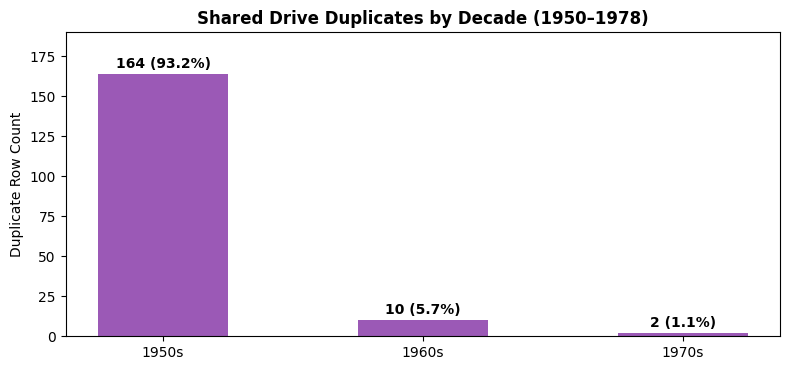

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(dup_decade_counts.index, dup_decade_counts.values, color="#9b59b6", width=0.5)
ax.set_title("Shared Drive Duplicates by Decade (1950–1978)", fontweight="bold")
ax.set_ylabel("Duplicate Row Count")
ax.set_ylim(0, 190)
for bar in bars:
    y = bar.get_height()
    pct = y / dup_decade_counts.sum() * 100
    ax.text(bar.get_x() + bar.get_width()/2, y + 4, f"{y} ({pct:.1f}%)", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### 1.8 Deduplication Rule & Verification
**Rule Choice & Domain Justification**:
1. Priority 1: Retain the car the driver **started the race in** (`grid > 0`). Our model makes pre-race predictions based on grid positions before lights out.
2. Priority 2: If both records have grid positions (or neither), retain the car with the superior finishing position (lower `positionOrder`).

In [20]:
res["started_car"] = (res["grid"] > 0).astype(int)

results_dedup = res.sort_values(
    by=["raceId", "driverId", "started_car", "positionOrder"],
    ascending=[True, True, False, True]
).drop_duplicates(subset=["raceId", "driverId"], keep="first").drop(columns=["started_car"]).copy()

print(f"Deduplicated result rows: {len(results_dedup):,}")
assert not results_dedup.duplicated(subset=["raceId", "driverId"]).any(), "Grain violation detected!"
print("[PASS] Modeling grain verified: Exactly 1 row per (raceId, driverId).")

Deduplicated result rows: 26,668
[PASS] Modeling grain verified: Exactly 1 row per (raceId, driverId).


### 1.8.1 Historical Edge Cases: Indianapolis 500 & Non-Qualifiers (DNQ)
We retain every raw row for auditing, but use a narrower population for modeling. Indianapolis 500 events (1950–1960) are excluded from the modeling table because they ran under a materially different USAC context. Confirmed `Did not qualify`, `Did not prequalify`, and `Withdrew` entries are also excluded because they were not race-start predictions. Pit-lane starters remain: `grid == 0` alone is not an exclusion rule. This choice reduces early-era coverage, so model findings should not be generalized uncritically to those excluded historical contexts.

In [21]:
indy_races = cleaned_dfs["races"][cleaned_dfs["races"]["name"].str.contains("Indianapolis 500", case=False, na=False)]
indy_race_ids = set(indy_races["raceId"])

non_starter_statuses = {"Did not qualify", "Did not prequalify", "Withdrew", "Did not start"}
non_starter_status_ids = set(cleaned_dfs["status"].loc[
    cleaned_dfs["status"]["status"].isin(non_starter_statuses), "statusId"
])
dnq_status_ids = set(cleaned_dfs["status"].loc[
    cleaned_dfs["status"]["status"].isin({"Did not qualify", "Did not prequalify"}), "statusId"
])
dnq_entries = results_dedup[results_dedup["statusId"].isin(dnq_status_ids)]

modeling_exclusion_mask = (
    results_dedup["raceId"].isin(indy_race_ids)
    | results_dedup["statusId"].isin(non_starter_status_ids)
)
modeling_results = results_dedup.loc[~modeling_exclusion_mask].copy()

print(f"Total Indianapolis 500 races excluded from modeling: {len(indy_races)}")
print(f"Total DNQ/DNPQ entries excluded from modeling: {len(dnq_entries):,}")
print(f"Total non-starter rows excluded from modeling: {results_dedup['statusId'].isin(non_starter_status_ids).sum():,}")
print(f"Modeling rows retained after historical policy: {len(modeling_results):,}")
assert not modeling_results.duplicated(["raceId", "driverId"]).any()


Total Indianapolis 500 races excluded from modeling: 11
Total DNQ/DNPQ entries excluded from modeling: 1,354
Total non-starter rows excluded from modeling: 1,601
Modeling rows retained after historical policy: 24,686


### 1.9 Post-Cleaning EDA: Historical Qualifying Coverage Drift
The `qualifying.csv` table records detailed knockout times only from 1994 onwards (0% coverage before 1994). This empirical finding proves that our modeling pipeline must use `results.grid` as the primary pre-race starting position to avoid dropping historical races.

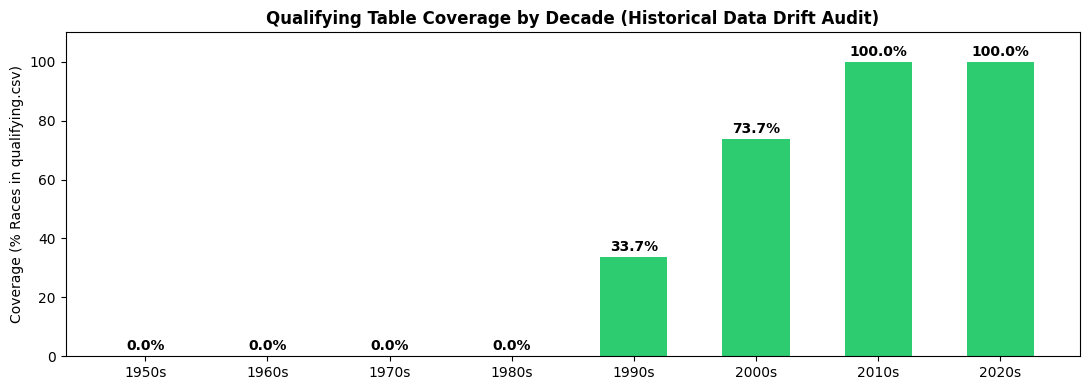

Audit Insight: qualifying.csv coverage is 0% before 1994.
Conclusion: Fallback to results.grid is mandatory for historical data integrity.


In [22]:
audit_races = results_dedup.merge(cleaned_dfs["races"][["raceId", "year"]], on="raceId")
qual_race_ids = set(cleaned_dfs["qualifying"]["raceId"].unique())
audit_races["has_qualifying"] = audit_races["raceId"].isin(qual_race_ids)

coverage = audit_races.groupby((audit_races["year"] // 10) * 10)["has_qualifying"].agg(["count", "mean"]).reset_index()
coverage["decade"] = coverage["year"].astype(str) + "s"

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(coverage["decade"], coverage["mean"] * 100, color="#2ecc71", width=0.55)
ax.set_title("Qualifying Table Coverage by Decade (Historical Data Drift Audit)", fontweight="bold")
ax.set_ylabel("Coverage (% Races in qualifying.csv)")
ax.set_ylim(0, 110)
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 2, f"{y:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

print("Audit Insight: qualifying.csv coverage is 0% before 1994.")
print("Conclusion: Fallback to results.grid is mandatory for historical data integrity.")

<a id="2"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Step 2: Multi-Hop Relational Analysis</p>

### 2.1 Question 1: Front-Row Start to Podium Conversion by Circuit
* **Query Goal**: Which circuits convert a front-row start (`grid in (1, 2)`) into a podium (`positionOrder <= 3`) most frequently? Does this ranking change in the post-2014 turbo-hybrid era?
* **Domain Distinction (Qualifying Pace vs. Starting Grid)**: We distinguish between **qualifying position** (`qualifying.position`, raw single-lap pace) and **starting grid** (`results.grid`, physical track position after engine/gearbox grid penalties). In F1, grid penalties alter physical starting positions, making `results.grid` the true starting track condition before lights out.
* **Relational Join Graph**: `results_dedup` $\bowtie$ `races` $\bowtie$ `circuits`.
* **Sample Size Threshold**: Restricted to circuits with at least 20 historical front-row starts to eliminate small-sample variance.

In [23]:
df_q1 = results_dedup.merge(cleaned_dfs["races"][["raceId", "year", "circuitId"]], on="raceId")
df_q1 = df_q1.merge(cleaned_dfs["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit_name"}), on="circuitId")
df_q1["is_podium"] = (df_q1["positionOrder"] <= 3).astype(int)
df_q1["era"] = np.where(df_q1["year"] >= 2014, "Hybrid Era (2014-2024)", "Pre-Hybrid (<2014)")

front_row = df_q1[df_q1["grid"].isin([1, 2])].copy()

circuit_starts = front_row.groupby("circuit_name")["is_podium"].count()
frequent_circuits = circuit_starts[circuit_starts >= 20].index

q1_summary = front_row[front_row["circuit_name"].isin(frequent_circuits)].groupby(
    ["circuit_name", "era"]
)["is_podium"].agg(starts="count", conversion_rate="mean").unstack()

q1_sorted = q1_summary.sort_values(("conversion_rate", "Hybrid Era (2014-2024)"), ascending=False)

q1_display = pd.DataFrame({
    "Circuit": q1_sorted.index,
    "Pre-Hybrid Starts": q1_sorted[("starts", "Pre-Hybrid (<2014)")].fillna(0).astype(int),
    "Pre-Hybrid Conversion Rate": (q1_sorted[("conversion_rate", "Pre-Hybrid (<2014)")] * 100).round(1).astype(str) + "%",
    "Hybrid Starts": q1_sorted[("starts", "Hybrid Era (2014-2024)")].fillna(0).astype(int),
    "Hybrid Conversion Rate": (q1_sorted[("conversion_rate", "Hybrid Era (2014-2024)")] * 100).round(1).astype(str) + "%"
}).reset_index(drop=True)
display(q1_display.head(10))


,Circuit,Pre-Hybrid Starts,Pre-Hybrid Conversion Rate,Hybrid Starts,Hybrid Conversion Rate
0,Suzuka Circuit,50,70.0%,18,88.9%
1,Circuit Park Zandvoort,60,58.3%,8,87.5%
2,Yas Marina Circuit,10,60.0%,22,86.4%
3,Sepang International Circuit,30,70.0%,7,85.7%
4,Circuit de Monaco,120,49.2%,20,85.0%
5,Circuit de Barcelona-Catalunya,46,65.2%,22,81.8%
6,Circuit de Spa-Francorchamps,89,55.1%,22,81.8%
7,Circuit of the Americas,4,100.0%,20,80.0%
8,Autódromo José Carlos Pace,62,59.7%,19,78.9%
9,Shanghai International Circuit,20,65.0%,14,78.6%


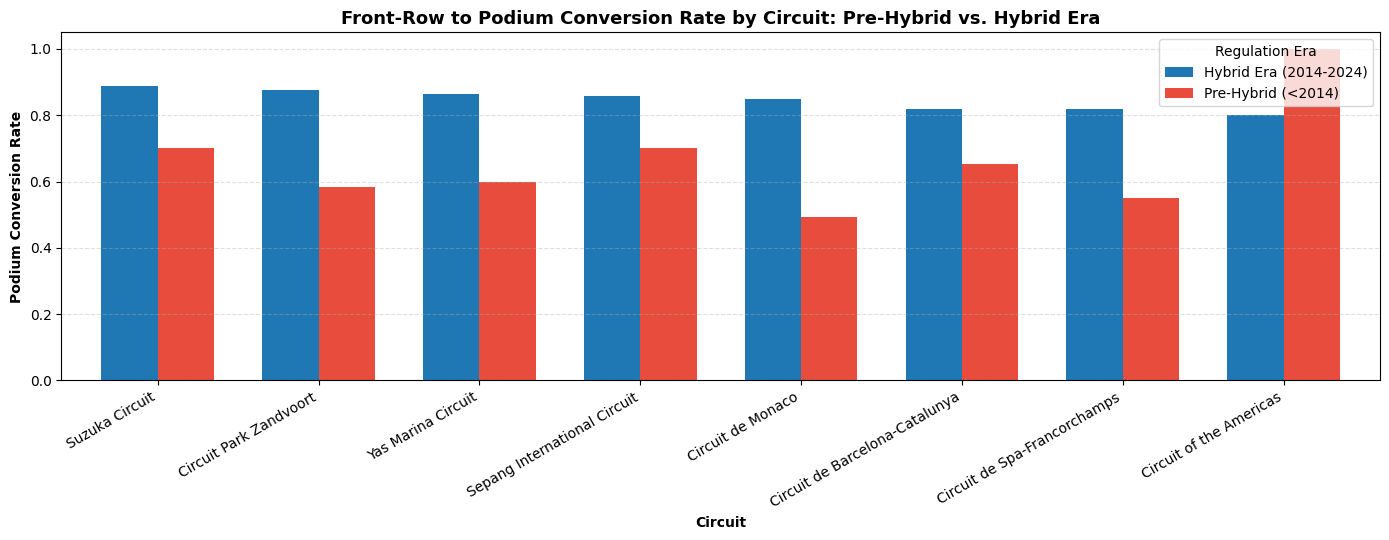

In [24]:
fig, ax = plt.subplots(figsize=(14, 5.5))
top_plot = q1_sorted.head(8)["conversion_rate"]
top_plot.plot(kind="bar", ax=ax, width=0.7, color=["#1f77b4", "#e74c3c"])
ax.set_title("Front-Row to Podium Conversion Rate by Circuit: Pre-Hybrid vs. Hybrid Era", fontsize=13, fontweight="bold")
ax.set_ylabel("Podium Conversion Rate", fontweight="bold")
ax.set_xlabel("Circuit", fontweight="bold")
ax.set_ylim(0, 1.05)
ax.legend(title="Regulation Era", frameon=True)
plt.xticks(rotation=30, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


#### Question 1 Empirical Findings & Domain Insights:
1. **Circuit comparison**: Use the displayed ranking and sample sizes to identify circuits with the highest historical front-row-to-podium conversion. Small-sample circuits are excluded by the stated threshold.
2. **Era comparison**: Compare the pre- and post-2014 rates in the chart rather than relying on fixed values in prose. Any differences are descriptive: they may reflect regulation changes, field strength, calendar composition, or other unobserved factors.
3. **Grid versus qualifying**: The analysis uses the actual starting grid, not qualifying position, because penalties can change the physical race-start order. This makes grid a valid pre-race predictor but does not establish that it independently causes a podium.

### 2.2 Question 2: Driver Home-Race Advantage Controlled for Grid Position
* **Query Goal**: Do drivers finish on the podium more often when racing in their home country, after controlling for grid position?
* **The Confounding Risk**: An unstratified comparison is biased by car performance. Top drivers (e.g., Lewis Hamilton at Silverstone, Max Verstappen at Zandvoort, Michael Schumacher at Hockenheim) frequently race at home in championship-caliber cars, creating an illusion of a "home-race boost".
* **Multi-Hop Relational Join Graph**: `results_dedup` $\bowtie$ `drivers` $\bowtie$ `races` $\bowtie$ `circuits`.
* **Controlled Stratification**: We map driver nationalities to circuit host countries and stratify starting grid positions into 4 distinct performance tiers:
  * `Front Grid (P1–P3)`
  * `Row 2–3 (P4–P6)`
  * `Midfield (P7–P10)`
  * `Backmarkers (P11+)`

In [25]:
nat_to_country = {
    "American": "USA", "Argentine": "Argentina", "Argentinian": "Argentina",
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
    "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chilean": "Chile", "Chinese": "China", "Colombian": "Colombia",
    "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands",
    "East German": "Germany", "Finnish": "Finland", "French": "France",
    "German": "Germany", "Hungarian": "Hungary", "Indian": "India",
    "Indonesian": "Indonesia", "Irish": "Ireland", "Italian": "Italy",
    "Japanese": "Japan", "Liechtensteiner": "Liechtenstein", "Malaysian": "Malaysia",
    "Mexican": "Mexico", "Monegasque": "Monaco", "New Zealander": "New Zealand",
    "Polish": "Poland", "Portuguese": "Portugal", "Rhodesian": "Zimbabwe",
    "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain",
    "Swedish": "Sweden", "Swiss": "Switzerland", "Thai": "Thailand",
    "Uruguayan": "Uruguay", "Venezuelan": "Venezuela"
}

df_q2 = results_dedup.merge(cleaned_dfs["drivers"][["driverId", "nationality"]], on="driverId")
df_q2 = df_q2.merge(cleaned_dfs["races"][["raceId", "circuitId"]], on="raceId")
df_q2 = df_q2.merge(cleaned_dfs["circuits"][["circuitId", "country"]], on="circuitId")

df_q2["nationality_clean"] = df_q2["nationality"].str.strip()
df_q2["driver_country"] = df_q2["nationality_clean"].map(nat_to_country)
df_q2["is_home_race"] = np.where(
    df_q2["driver_country"].notna(),
    (df_q2["driver_country"] == df_q2["country"]).astype(int),
    np.nan
)
df_q2["is_podium"] = (df_q2["positionOrder"] <= 3).astype(int)

unmapped_nationalities = sorted(df_q2.loc[df_q2["driver_country"].isna(), "nationality"].dropna().unique())
print(f"Home-country mapping coverage: {df_q2['driver_country'].notna().mean():.2%}")
print(f"Unmapped/ambiguous nationalities excluded from Question 2: {unmapped_nationalities}")

df_q2_valid = df_q2[(df_q2["grid"] > 0) & (df_q2["grid"] <= 24)].dropna(subset=["is_home_race"]).copy()
df_q2_valid["grid_bucket"] = pd.cut(
    df_q2_valid["grid"],
    bins=[0, 3, 6, 10, 24],
    labels=["Front Grid (P1-P3)", "Row 2-3 (P4-P6)", "Midfield (P7-P10)", "Backmarkers (P11+)"]
)

q2_strat = df_q2_valid.groupby(["grid_bucket", "is_home_race"], observed=False).agg(
    starts=("is_podium", "count"),
    podiums=("is_podium", "sum"),
    podium_rate=("is_podium", "mean")
).reset_index()

q2_pivot = q2_strat.pivot(index="grid_bucket", columns="is_home_race", values="podium_rate")
q2_pivot.columns = ["Away Race Podium Rate", "Home Race Podium Rate"]

q2_display = (q2_pivot * 100).round(2).astype(str) + "%"
q2_display = q2_display.reset_index().rename(columns={"grid_bucket": "Starting Grid Bucket"})
display(q2_display)


Home-country mapping coverage: 99.99%
Unmapped/ambiguous nationalities excluded from Question 2: ['American-Italian', 'Argentine-Italian']


,Starting Grid Bucket,Away Race Podium Rate,Home Race Podium Rate
0,Front Grid (P1-P3),55.54%,54.92%
1,Row 2-3 (P4-P6),26.12%,24.62%
2,Midfield (P7-P10),9.34%,8.79%
3,Backmarkers (P11+),1.73%,1.55%


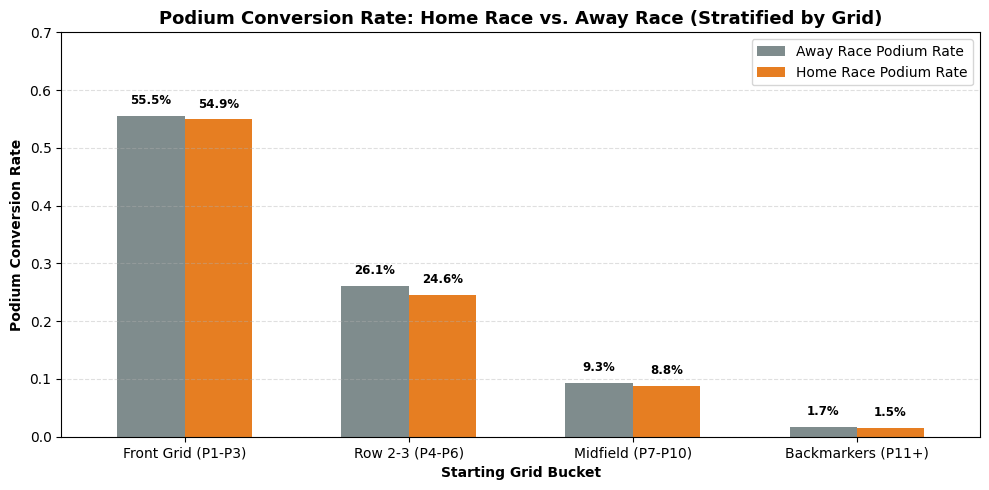

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
q2_pivot.plot(kind="bar", ax=ax, color=["#7f8c8d", "#e67e22"], width=0.6)
ax.set_title("Podium Conversion Rate: Home Race vs. Away Race (Stratified by Grid)", fontsize=13, fontweight="bold")
ax.set_ylabel("Podium Conversion Rate", fontweight="bold")
ax.set_xlabel("Starting Grid Bucket", fontweight="bold")
ax.set_ylim(0, 0.7)
ax.legend(frameon=True)
for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val*100:.1f}%", (p.get_x() + p.get_width() / 2., val + 0.015),
                    ha="center", va="bottom", fontsize=8.5, fontweight="bold")
plt.xticks(rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


### 2.2.1 Hypothesis Testing: Chi-Square (\(\chi^2\) / χ²) Test of Independence for Home Advantage
To rigorously verify whether the minor differences observed between home and away podium rates are statistically meaningful or merely random variance, we conduct formal Pearson Chi-Square ($\chi^2$) Contingency Tests across each grid tier and across the unstratified population ($\alpha = 0.05$).

In [27]:
q2_chi2_records = []
buckets = ["Front Grid (P1-P3)", "Row 2-3 (P4-P6)", "Midfield (P7-P10)", "Backmarkers (P11+)"]
for b in buckets:
    sub = df_q2_valid[df_q2_valid["grid_bucket"] == b]
    ct = pd.crosstab(sub["is_home_race"], sub["is_podium"])
    stat, p_val, _, _ = chi2_contingency(ct)
    q2_chi2_records.append({
        "Starting Grid Bucket": b,
        "Away Starts": int((sub["is_home_race"] == 0).sum()),
        "Away Podiums": int(((sub["is_home_race"] == 0) & (sub["is_podium"] == 1)).sum()),
        "Home Starts": int((sub["is_home_race"] == 1).sum()),
        "Home Podiums": int(((sub["is_home_race"] == 1) & (sub["is_podium"] == 1)).sum()),
        "Chi2 Stat": round(stat, 3),
        "p-value": round(p_val, 4),
        "Statistical Significance (alpha=0.05)": "Not Significant (p > 0.05)" if p_val >= 0.05 else "Significant (p < 0.05)"
    })

ct_all = pd.crosstab(df_q2_valid["is_home_race"], df_q2_valid["is_podium"])
stat_all, p_all, _, _ = chi2_contingency(ct_all)
q2_chi2_records.append({
    "Starting Grid Bucket": "Overall (Unstratified Confounding)",
    "Away Starts": int((df_q2_valid["is_home_race"] == 0).sum()),
    "Away Podiums": int(((df_q2_valid["is_home_race"] == 0) & (df_q2_valid["is_podium"] == 1)).sum()),
    "Home Starts": int((df_q2_valid["is_home_race"] == 1).sum()),
    "Home Podiums": int(((df_q2_valid["is_home_race"] == 1) & (df_q2_valid["is_podium"] == 1)).sum()),
    "Chi2 Stat": round(stat_all, 3),
    "p-value": round(p_all, 4),
    "Statistical Significance (alpha=0.05)": "Significant (p < 0.05)" if p_all < 0.05 else "Not Significant (p > 0.05)"
})
q2_chi2_table = pd.DataFrame(q2_chi2_records)
display(q2_chi2_table)

,Starting Grid Bucket,Away Starts,Away Podiums,Home Starts,Home Podiums,Chi2 Stat,p-value,Statistical Significance (alpha=0.05)
0,Front Grid (P1-P3),3106,1725,264,145,0.016,0.8981,Not Significant (p > 0.05)
1,Row 2-3 (P4-P6),3109,812,260,64,0.209,0.6477,Not Significant (p > 0.05)
2,Midfield (P7-P10),4123,385,387,34,0.071,0.7900,Not Significant (p > 0.05)
3,Backmarkers (P11+),11841,205,1229,19,0.130,0.7181,Not Significant (p > 0.05)
4,Overall (Unstratified Confounding),22179,3127,2140,262,5.451,0.0196,Significant (p < 0.05)


#### Question 2 Interpretation
The table and chi-square tests above use only drivers with a mapped, unambiguous nationality-to-country relationship; ambiguous dual-nationality entries are excluded rather than misclassified as away races. Interpret the stratified differences and p-values from the final run as associations after coarse grid-position control, not evidence that nationality or crowd effects cause race outcomes. The contribution of `is_home_race` to the predictive model is assessed separately by the validation ablation.

### 2.3 Question 3: Constructor Mechanical-Retirement Rates Across Engine Eras
* **Query Goal**: Which constructors experienced the highest mechanical retirement rates in the 2014–2021 turbo-hybrid era versus the 2022–2024 ground-effect era?
* **Domain Classification Methodology**: The Ergast `status.csv` table catalogs 141 granular status descriptions. We systematically classify pure **Mechanical Failures** (Engine, Gearbox, Power Unit, Hydraulics, Electrical, Turbo, ERS, Overheating, Differential, Suspension, etc.) separately from accidents, collisions, punctures, and classified race finishes.
* **Multi-Hop Relational Join Graph**: `results_dedup` $\bowtie$ `status` $\bowtie$ `races` $\bowtie$ `constructors`.
* **Sample Size Threshold**: Minimum 30 starts per constructor within each era to filter out temporary or single-entry constructors.

In [28]:
status_df = cleaned_dfs["status"].copy()

# Explicit, reviewable component-failure mapping. Ambiguous operational/regulatory
# labels such as Technical, Refuelling, and Out of fuel are intentionally excluded.
mechanical_statuses = {
    "Engine", "Engine fire", "Engine misfire", "Gearbox", "Transmission", "Clutch",
    "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes", "Differential",
    "Overheating", "Mechanical", "Driveshaft", "Fuel pressure", "Water pressure",
    "Throttle", "Steering", "Exhaust", "Oil leak", "Fuel pump", "Oil pressure",
    "Pneumatics", "Fuel system", "Oil line", "Oil pump", "Fuel leak", "Turbo",
    "Fuel pipe", "Oil pipe", "Power Unit", "ERS", "Battery"
}
status_df["is_mechanical"] = status_df["status"].isin(mechanical_statuses).astype(int)

status_mapping_display = status_df.loc[
    status_df["status"].isin(mechanical_statuses | non_starter_statuses),
    ["statusId", "status", "is_mechanical"]
].sort_values("statusId").copy()
status_mapping_display["classification"] = np.where(
    status_mapping_display["is_mechanical"].eq(1),
    "Mechanical component failure",
    "Exclude from starter denominator"
)
display(status_mapping_display)

df_q3 = results_dedup.merge(status_df, on="statusId")
df_q3 = df_q3.merge(cleaned_dfs["races"][["raceId", "year"]], on="raceId")
df_q3 = df_q3.merge(cleaned_dfs["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor_name"}), on="constructorId")
df_q3 = df_q3[~df_q3["status"].isin(non_starter_statuses)].copy()

def compute_mech_rate(df_sub, era_name, min_starts=30):
    res = df_sub.groupby("constructor_name").agg(
        starts=("resultId", "count"),
        mech_dnfs=("is_mechanical", "sum"),
        mech_rate=("is_mechanical", "mean")
    ).reset_index()
    res = res[res["starts"] >= min_starts].sort_values("mech_rate", ascending=False)
    res["era"] = era_name
    return res

era1 = df_q3[(df_q3["year"] >= 2014) & (df_q3["year"] <= 2021)]
era2 = df_q3[(df_q3["year"] >= 2022) & (df_q3["year"] <= 2024)]

rates_era1 = compute_mech_rate(era1, "2014-2021 (Hybrid)", min_starts=30)
rates_era2 = compute_mech_rate(era2, "2022-2024 (Ground Effect)", min_starts=30)

comp = rates_era1[["constructor_name", "starts", "mech_dnfs", "mech_rate"]].merge(
    rates_era2[["constructor_name", "starts", "mech_dnfs", "mech_rate"]],
    on="constructor_name",
    suffixes=("_era1", "_era2")
)

comp["delta_mech_rate"] = (comp["mech_rate_era2"] - comp["mech_rate_era1"]) * 100
comp["rel_improvement"] = (comp["mech_rate_era1"] - comp["mech_rate_era2"]) / comp["mech_rate_era1"] * 100
comp = comp.sort_values(by="mech_rate_era1", ascending=False)

q3_unified_comparison = pd.DataFrame({
    "Constructor": comp["constructor_name"],
    "Hybrid Era Starts (2014-2021)": comp["starts_era1"],
    "Hybrid DNF Rate (%)": (comp["mech_rate_era1"] * 100).round(2).astype(str) + "%",
    "Ground Effect Starts (2022-2024)": comp["starts_era2"],
    "Ground Effect DNF Rate (%)": (comp["mech_rate_era2"] * 100).round(2).astype(str) + "%",
    "Absolute Delta (% Points)": comp["delta_mech_rate"].round(2).apply(lambda x: f"{x:+.2f}%"),
    "Reliability Gain (%)": comp["rel_improvement"].round(2).apply(lambda x: f"{x:+.1f}%")
})

print("Unified Constructor Reliability Evolution: Hybrid Era (2014-2021) vs. Ground Effect Era (2022-2024)")
display(q3_unified_comparison)

,statusId,status,is_mechanical,classification
4,5,Engine,1,Mechanical component failure
5,6,Gearbox,1,Mechanical component failure
6,7,Transmission,1,Mechanical component failure
7,8,Clutch,1,Mechanical component failure
8,9,Hydraulics,1,Mechanical component failure
9,10,Electrical,1,Mechanical component failure
20,21,Radiator,1,Mechanical component failure
21,22,Suspension,1,Mechanical component failure
22,23,Brakes,1,Mechanical component failure
23,24,Differential,1,Mechanical component failure


Unified Constructor Reliability Evolution: Hybrid Era (2014-2021) vs. Ground Effect Era (2022-2024)


,Constructor,Hybrid Era Starts (2014-2021),Hybrid DNF Rate (%),Ground Effect Starts (2022-2024),Ground Effect DNF Rate (%),Absolute Delta (% Points),Reliability Gain (%)
0,McLaren,318,12.58%,136,3.68%,-8.90%,+70.8%
1,Sauber,200,10.5%,48,2.08%,-8.42%,+80.2%
2,AlphaTauri,78,10.26%,88,6.82%,-3.44%,+33.5%
3,Red Bull,319,9.4%,136,3.68%,-5.73%,+60.9%
4,Williams,319,7.21%,134,5.22%,-1.99%,+27.6%
5,Haas F1 Team,241,7.05%,135,3.7%,-3.35%,+47.5%
6,Alpine F1 Team,44,6.82%,136,9.56%,+2.74%,-40.2%
7,Mercedes,320,3.75%,136,4.41%,+0.66%,-17.6%
8,Ferrari,320,3.44%,136,5.88%,+2.44%,-71.1%
9,Alfa Romeo,120,3.33%,88,7.95%,+4.62%,-138.6%


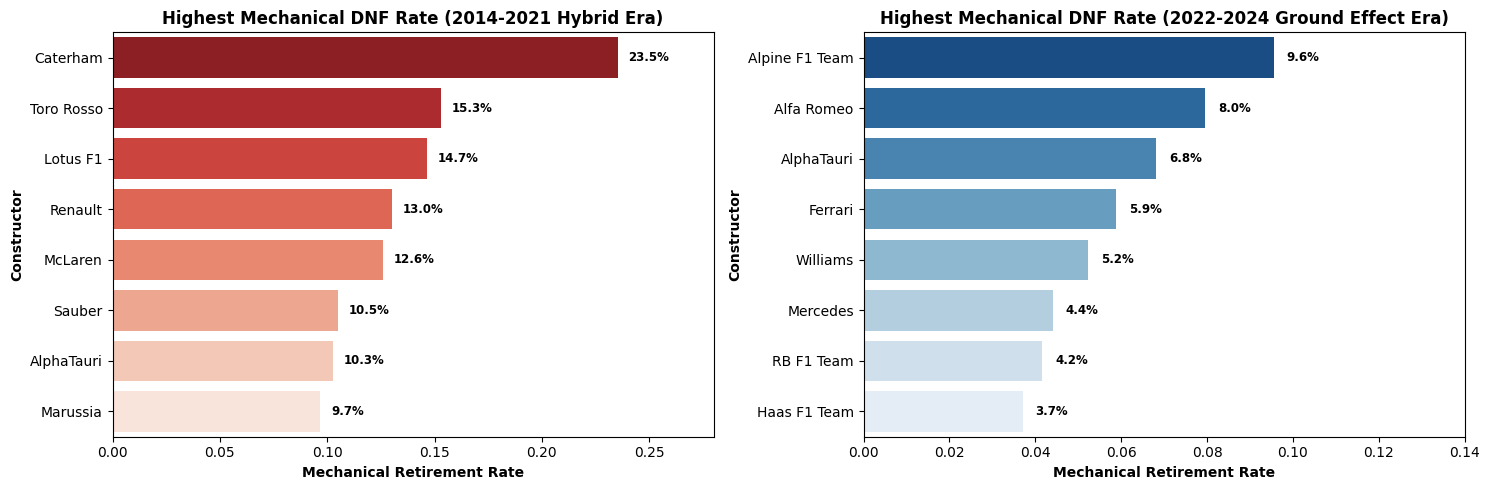

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=rates_era1.head(8), x="mech_rate", y="constructor_name", hue="constructor_name", legend=False, ax=axes[0], palette="Reds_r")
axes[0].set_title("Highest Mechanical DNF Rate (2014-2021 Hybrid Era)", fontweight="bold")
axes[0].set_xlabel("Mechanical Retirement Rate", fontweight="bold")
axes[0].set_ylabel("Constructor", fontweight="bold")
axes[0].set_xlim(0, 0.28)
for p in axes[0].patches:
    val = p.get_width()
    axes[0].annotate(f"{val*100:.1f}%", (val + 0.005, p.get_y() + p.get_height() / 2.),
                     va="center", fontsize=8.5, fontweight="bold")

sns.barplot(data=rates_era2.head(8), x="mech_rate", y="constructor_name", hue="constructor_name", legend=False, ax=axes[1], palette="Blues_r")
axes[1].set_title("Highest Mechanical DNF Rate (2022-2024 Ground Effect Era)", fontweight="bold")
axes[1].set_xlabel("Mechanical Retirement Rate", fontweight="bold")
axes[1].set_ylabel("Constructor", fontweight="bold")
axes[1].set_xlim(0, 0.14)
for p in axes[1].patches:
    val = p.get_width()
    axes[1].annotate(f"{val*100:.1f}%", (val + 0.003, p.get_y() + p.get_height() / 2.),
                     va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()


#### Question 3 Interpretation
The comparison above reports only rows classified by the explicit component-failure status mapping and excludes confirmed non-starters from the denominator. Rankings should be read with each constructor's displayed start count and only as descriptive associations; they do not establish that a regulation era caused a particular failure rate. The current podium model does not use this post-race reliability result as a feature.

<a id="3"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Step 3: Leakage-Safe Feature Engineering</p>

### 3.1 Chronological Base Dataset Assembly
We merge the policy-filtered `modeling_results` table with race, driver, circuit, and constructor metadata, then sort chronologically by `["date", "round", "raceId"]`. This chronological ordering is essential when calculating historical rolling metrics and cumulative standings.

In [30]:
modeling_df = modeling_results.merge(
    cleaned_dfs["races"][["raceId", "year", "round", "circuitId", "date", "name"]],
    on="raceId", how="inner", suffixes=("", "_race")
).merge(
    cleaned_dfs["drivers"][["driverId", "dob", "nationality"]], on="driverId", how="left"
).merge(
    cleaned_dfs["circuits"][["circuitId", "country", "alt"]], on="circuitId", how="left"
).merge(
    cleaned_dfs["constructors"][["constructorId", "name"]], on="constructorId", how="left", suffixes=("", "_constructor")
).sort_values(["date", "round", "raceId"]).reset_index(drop=True)

modeling_df["is_podium"] = (modeling_df["positionOrder"] <= 3).astype(int)
print(f"Base modeling dataset assembled: {len(modeling_df):,} rows across {modeling_df['year'].nunique()} seasons.")


Base modeling dataset assembled: 24,686 rows across 75 seasons.


### 3.2 Pre-Race Championship Standings (Strictly Shifted)
* **Target Leakage Trap**: Using standard cumulative points (`cumsum()`) would include points earned *in the current race*, creating catastrophic lookahead bias.
* **Leakage-Safe Formulation**: We compute `driver_season_pts_before = cumsum(points) - points`, strictly reflecting points accumulated prior to lights out. Constructor season points and race counts are similarly aggregated and lagged.

In [31]:
modeling_df["driver_season_pts_before"] = modeling_df.groupby(["year", "driverId"])["points"].cumsum() - modeling_df["points"]
modeling_df["driver_season_podiums_before"] = modeling_df.groupby(["year", "driverId"])["is_podium"].cumsum() - modeling_df["is_podium"]
modeling_df["driver_season_races_before"] = modeling_df.groupby(["year", "driverId"]).cumcount()

const_pts = modeling_df.groupby(["raceId", "constructorId"])["points"].sum().reset_index()
const_pts = const_pts.merge(cleaned_dfs["races"][["raceId", "year", "date", "round"]], on="raceId").sort_values(["date", "round"])
const_pts["constructor_season_pts_before"] = const_pts.groupby(["year", "constructorId"])["points"].cumsum() - const_pts["points"]
const_pts["constructor_season_races_before"] = const_pts.groupby(["year", "constructorId"]).cumcount()

modeling_df = modeling_df.merge(
    const_pts[["raceId", "constructorId", "constructor_season_pts_before", "constructor_season_races_before"]],
    on=["raceId", "constructorId"], how="left"
)
print("Pre-race championship standings engineered with zero lookahead bias.")


Pre-race championship standings engineered with zero lookahead bias.


### 3.3 Rolling Momentum & Team Form Features
Recent performance is a strong indicator of current car setup and driver confidence. We calculate:
* **`driver_form_podiums_last5`**: Rolling podium rate across the driver's prior 5 completed races.
* **`constructor_form_podiums_last10`**: Rolling podium conversion rate across the constructor's prior 10 Grand Prix events.
* **Strict Lagging & Intra-Team Leakage Prevention**: We apply `.shift(1)` before computing rolling windows. For constructors, statistics are aggregated at the race-level before lagging and merged back, ensuring teammates entering the same Grand Prix share identical historical team form with zero intra-race teammate lookahead.

In [32]:
modeling_df["driver_form_podiums_last5"] = modeling_df.groupby("driverId")["is_podium"].transform(
    lambda x: x.shift(1).rolling(5, min_periods=1).mean()
).fillna(0)

const_race = modeling_df.groupby(["raceId", "constructorId", "date", "round"])["is_podium"].mean().reset_index()
const_race = const_race.sort_values(["date", "round", "raceId"]).reset_index(drop=True)
const_race["constructor_form_podiums_last10"] = const_race.groupby("constructorId")["is_podium"].transform(
    lambda x: x.shift(1).rolling(10, min_periods=1).mean()
).fillna(0)

modeling_df = modeling_df.merge(
    const_race[["raceId", "constructorId", "constructor_form_podiums_last10"]],
    on=["raceId", "constructorId"],
    how="left"
)
print("Rolling form engineered with strictly lagged windows (.shift(1)) and race-level constructor aggregation.")

Rolling form engineered with strictly lagged windows (.shift(1)) and race-level constructor aggregation.


### 3.4 Demographics, Career Experience & Starting Context
We engineer features capturing driver maturity, career experience, and track context:
* **`driver_age`**: Exact age in fractional years at race date (`(date - dob) / 365.25`).
* **`driver_career_starts`**: Cumulative career race starts up to this race.
* **`is_front_row`**: Starting on the front row (`grid in [1, 2]`).
* **`is_home_race`**: Driver nationality matching circuit host country.

In [33]:
modeling_df["driver_age"] = (modeling_df["date"] - modeling_df["dob"]).dt.days / 365.25
modeling_df["driver_career_starts"] = modeling_df.groupby("driverId").cumcount()
modeling_df["is_front_row"] = modeling_df["grid"].isin([1, 2]).astype(int)
modeling_df["driver_country"] = modeling_df["nationality"].str.strip().map(nat_to_country)
modeling_df["is_home_race"] = np.where(
    modeling_df["driver_country"].notna(),
    (modeling_df["driver_country"] == modeling_df["country"]).astype(int),
    np.nan
)
print("Demographic, experience, and grid context features computed.")


Demographic, experience, and grid context features computed.


### 3.5 Qualifying Coverage Drift Handling & Penalty Tracking
* **Historical Drift Reality**: As demonstrated in Step 1.9, detailed qualifying coverage is absent in earlier eras. Dropping rows with missing qualifying would unnecessarily discard a substantial historical portion of the retained modeling population.
* **Robust Fallback Strategy**:
  * `qual_missing`: Binary indicator tracking whether qualifying records exist.
  * `qual_position_imputed`: Uses qualifying position when available; falls back cleanly to `grid` for pre-1994 races.
  * `grid_penalty`: Shift between grid and qualifying position (`grid - qual_position_imputed`), directly capturing grid drops from engine penalties or technical infringements.

In [34]:
qual_sub = cleaned_dfs["qualifying"][["raceId", "driverId", "position"]].drop_duplicates(["raceId", "driverId"])
qual_sub = qual_sub.rename(columns={"position": "qual_position"})
modeling_df = modeling_df.merge(qual_sub, on=["raceId", "driverId"], how="left")

modeling_df["qual_missing"] = modeling_df["qual_position"].isna().astype(int)
modeling_df["qual_position_imputed"] = modeling_df["qual_position"].fillna(modeling_df["grid"])
modeling_df["grid_penalty"] = modeling_df["grid"] - modeling_df["qual_position_imputed"]
print("Qualifying data integrated with robust pre-1994 fallback architecture.")


Qualifying data integrated with robust pre-1994 fallback architecture.


### 3.6 Final Feature Matrix Inspection & Correlation Analysis
We assemble the complete 15-feature matrix, verify summary statistics, and evaluate Pearson correlation against our target `is_podium`.

Feature Matrix Shape: (24686, 15)


,grid,qual_position_imputed,grid_penalty,qual_missing,is_front_row,driver_age,driver_season_pts_before,driver_season_podiums_before,driver_season_races_before,constructor_season_pts_before,constructor_season_races_before,driver_form_podiums_last5,constructor_form_podiums_last10,driver_career_starts,is_home_race
count,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24686.00,24683.00
mean,11.72,11.78,-0.06,0.58,0.09,29.91,17.92,0.99,6.77,37.74,7.38,0.13,0.14,68.09,0.08
std,6.78,6.76,1.33,0.49,0.29,5.24,41.21,2.12,5.21,79.64,5.16,0.24,0.19,68.98,0.27
min,0.00,0.00,-28.00,0.00,0.00,17.45,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,6.00,6.00,0.00,0.00,0.00,26.07,0.00,0.00,2.00,0.00,3.00,0.00,0.00,15.00,0.00
50%,12.00,12.00,0.00,1.00,0.00,29.36,3.00,0.00,6.00,9.00,7.00,0.00,0.05,45.00,0.00
75%,17.00,17.00,0.00,1.00,0.00,33.23,16.00,1.00,11.00,36.50,11.00,0.20,0.23,100.00,0.00
max,34.00,34.00,23.00,1.00,1.00,56.77,504.00,20.00,23.00,752.00,23.00,1.00,1.00,401.00,1.00


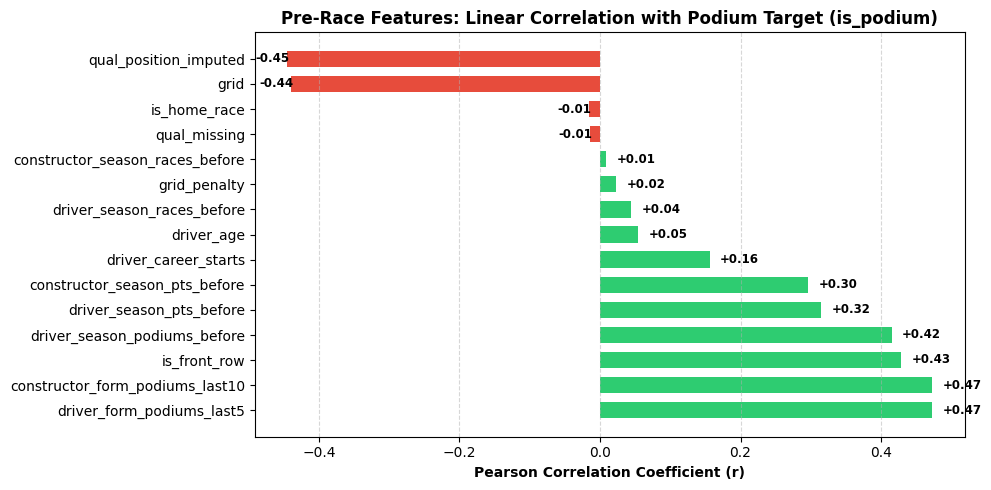

In [35]:
feature_columns = [
    "grid", "qual_position_imputed", "grid_penalty", "qual_missing", "is_front_row",
    "driver_age", "driver_season_pts_before", "driver_season_podiums_before",
    "driver_season_races_before", "constructor_season_pts_before", "constructor_season_races_before",
    "driver_form_podiums_last5", "constructor_form_podiums_last10", "driver_career_starts", "is_home_race"
]

print(f"Feature Matrix Shape: {modeling_df[feature_columns].shape}")
display(modeling_df[feature_columns].describe().round(2))

corr_series = modeling_df[feature_columns + ["is_podium"]].corr()["is_podium"].drop("is_podium").sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#2ecc71" if x > 0 else "#e74c3c" for x in corr_series.values]
bars = ax.barh(corr_series.index, corr_series.values, color=colors, height=0.65)
ax.set_title("Pre-Race Features: Linear Correlation with Podium Target (is_podium)", fontsize=12, fontweight="bold")
ax.set_xlabel("Pearson Correlation Coefficient (r)", fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)
for bar in bars:
    w = bar.get_width()
    offset = 0.015 if w >= 0 else -0.045
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:+.2f}", va="center", fontsize=8.5, fontweight="bold")
plt.tight_layout()
plt.show()


### 3.6.0 Pre-Modeling Feature Distribution & Outlier Audit (15 Engineered Features)
To verify data sanity across our final 15-feature modeling matrix, we classify each feature into continuous versus discrete domains, compute higher-order moments (skewness), and audit outlier prevalence under Tukey's 1.5 $\times$ IQR fences.

In [36]:
continuous_feats = [
    "driver_age", "driver_career_starts", "driver_season_pts_before",
    "constructor_season_pts_before", "driver_form_podiums_last5",
    "constructor_form_podiums_last10", "driver_season_races_before",
    "constructor_season_races_before", "driver_season_podiums_before"
]

outlier_records = []
for col in feature_columns:
    s = modeling_df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = s[(s < lower) | (s > upper)]
    f_type = "Continuous" if col in continuous_feats else "Discrete"
    skew_val = s.skew()
    
    outlier_records.append({
        "Feature Name": col,
        "Variable Type": f_type,
        "Mean": round(s.mean(), 2),
        "Median": round(s.median(), 2),
        "Std": round(s.std(), 2),
        "IQR": round(iqr, 2),
        "Skewness": round(skew_val, 2),
        "Lower Fence": round(lower, 2),
        "Upper Fence": round(upper, 2),
        "Outlier Count": len(outliers),
        "Outlier Pct": f"{len(outliers) / len(s) * 100:.2f}%",
        "Min": round(s.min(), 2),
        "Max": round(s.max(), 2)
    })

feature_audit_df = pd.DataFrame(outlier_records)
display(feature_audit_df)

,Feature Name,Variable Type,Mean,Median,Std,IQR,Skewness,Lower Fence,Upper Fence,Outlier Count,Outlier Pct,Min,Max
0,grid,Discrete,11.72,12.00,6.78,11.00,0.17,-10.50,33.50,1,0.00%,0.00,34.00
1,qual_position_imputed,Discrete,11.78,12.00,6.76,11.00,0.16,-10.50,33.50,1,0.00%,0.00,34.00
2,grid_penalty,Discrete,-0.06,0.00,1.33,0.00,-4.32,0.00,0.00,2495,10.11%,-28.00,23.00
3,qual_missing,Discrete,0.58,1.00,0.49,1.00,-0.31,-1.50,2.50,0,0.00%,0.00,1.00
4,is_front_row,Discrete,0.09,0.00,0.29,0.00,2.87,0.00,0.00,2217,8.98%,0.00,1.00
5,driver_age,Continuous,29.91,29.36,5.24,7.17,0.65,15.32,43.99,311,1.26%,17.45,56.77
6,driver_season_pts_before,Continuous,17.92,3.00,41.21,16.00,4.29,-24.00,40.00,2955,11.97%,0.00,504.00
7,driver_season_podiums_before,Continuous,0.99,0.00,2.12,1.00,3.05,-1.50,2.50,3348,13.56%,0.00,20.00
8,driver_season_races_before,Continuous,6.77,6.00,5.21,9.00,0.52,-11.50,24.50,0,0.00%,0.00,23.00
9,constructor_season_pts_before,Continuous,37.74,9.00,79.64,36.50,4.05,-54.75,91.25,2568,10.40%,0.00,752.00


#### Feature Distribution & Outlier Insights (Empirical Rationale for Step 4.3):
1. **Championship-points skewness**: Pre-race season points are strongly right-skewed because a small number of championship contenders accumulate far more points than most drivers and constructors. The table above reports the observed skewness and Tukey-fence rates.
2. **Grid-penalty distribution**: Large negative grid adjustments represent genuine sporting events, such as engine-replacement or technical penalties, rather than measurement errors.
3. **Treatment decision**: These values are retained. The controlled preprocessing experiment below evaluates whether clipping tails improves validation performance; that result, rather than a fixed narrative number, determines the final pipeline.

### 3.6.1 Multicollinearity Analysis: Feature-to-Feature Correlation Heatmap Matrix (15x15)
To understand multicollinearity among our 15 pre-race predictors and guide model regularization choices, we construct the full correlation heatmap matrix across all engineered features.

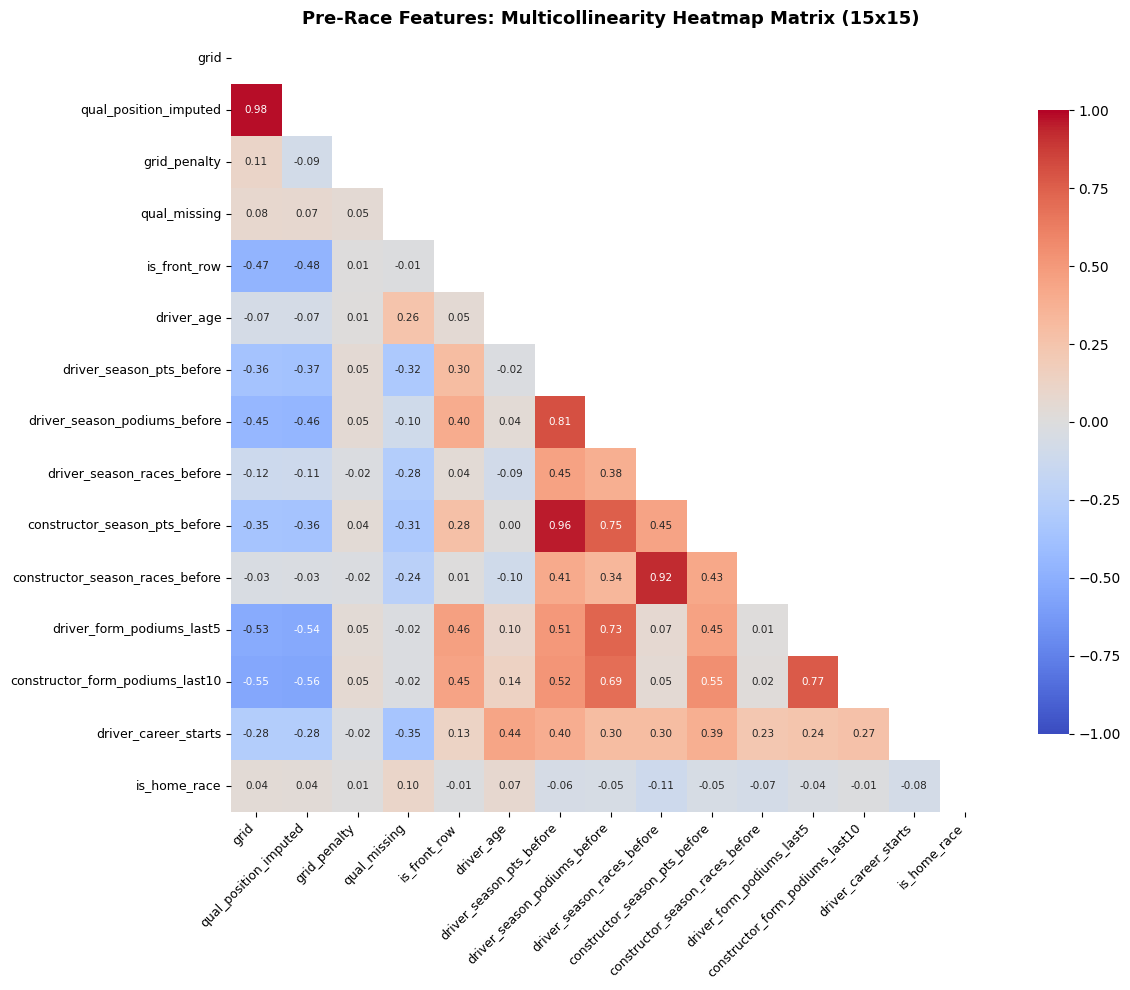

In [37]:
corr_matrix = modeling_df[feature_columns].corr()
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 7.5},
    ax=ax
)
ax.set_title("Pre-Race Features: Multicollinearity Heatmap Matrix (15x15)", fontsize=13, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

#### Multicollinearity Insights & Regularization Rationale:
1. **Correlation structure**: The heatmap shows expected relationships among starting position, qualifying context, and accumulated form. Use the displayed coefficients from this run rather than fixed values in prose.
2. **Modeling response**: Logistic Regression uses L2 regularization, while the tree models can distribute splits across correlated predictors. The benchmark below determines whether those choices generalize; correlation alone is not a reason to claim a feature is causal.

#### Feature Engineering Interpretation
Use the regenerated correlation chart as descriptive evidence for feature selection. Grid, qualifying context, and lagged form are valid pre-race inputs; correlation magnitudes are associations only and do not establish causal effects. The separately mapped `is_home_race` feature is retained only if its validation contribution supports it.

<a id="4"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Step 4: Strict Temporal Splitting & Preprocessing</p>

### 4.1 Strict Temporal Splitting Rationale & Partitioning
* **Causality & Lookahead Bias**: Standard random $k$-fold cross-validation is strictly forbidden in Formula 1 forecasting. Shuffling races allows a model trained on round 18 of a season to predict round 3 using "future" aerodynamic packages, mid-season tire compound updates, and driver momentum.
* **Strict Prospective Splits**:
  * **Train Split ($\le 2019$)**: Historical driver-race observations through 2019, after applying the documented modeling-population policy.
  * **Validation Split ($2020\text{--}2021$)**: The development period used for model comparison and threshold selection.
  * **Holdout Test Split ($2022\text{--}2024$)**: The out-of-sample ground-effect-era evaluation. The next cell reports the final row counts for every split.

In [38]:
train_mask = modeling_df["year"] <= 2019
val_mask = (modeling_df["year"] >= 2020) & (modeling_df["year"] <= 2021)
test_mask = modeling_df["year"] >= 2022

X_train_raw = modeling_df.loc[train_mask, feature_columns].copy()
y_train = modeling_df.loc[train_mask, "is_podium"].values

X_val_raw = modeling_df.loc[val_mask, feature_columns].copy()
y_val = modeling_df.loc[val_mask, "is_podium"].values

X_test_raw = modeling_df.loc[test_mask, feature_columns].copy()
y_test = modeling_df.loc[test_mask, "is_podium"].values

split_summary = pd.DataFrame([
    {"Split": "Train (<=2019)", "Total Rows": len(X_train_raw), "Podiums": int(y_train.sum()), "Podium Rate": f"{y_train.mean()*100:.2f}%", "Seasons": "1950-2019"},
    {"Split": "Validation (2020-2021)", "Total Rows": len(X_val_raw), "Podiums": int(y_val.sum()), "Podium Rate": f"{y_val.mean()*100:.2f}%", "Seasons": "2020-2021"},
    {"Split": "Test (2022-2024)", "Total Rows": len(X_test_raw), "Podiums": int(y_test.sum()), "Podium Rate": f"{y_test.mean()*100:.2f}%", "Seasons": "2022-2024"}
])
display(split_summary)


,Split,Total Rows,Podiums,Podium Rate,Seasons
0,Train (<=2019),22553,3038,13.47%,1950-2019
1,Validation (2020-2021),779,117,15.02%,2020-2021
2,Test (2022-2024),1354,204,15.07%,2022-2024


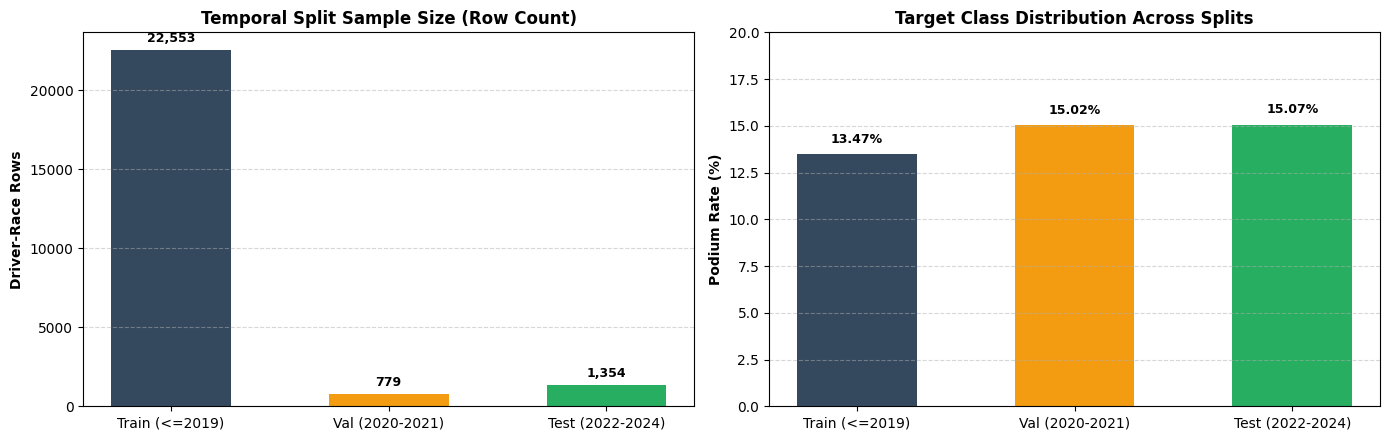

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

split_names = ["Train (<=2019)", "Val (2020-2021)", "Test (2022-2024)"]
row_counts = [len(X_train_raw), len(X_val_raw), len(X_test_raw)]
podium_rates = [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100]

b1 = axes[0].bar(split_names, row_counts, color=["#34495e", "#f39c12", "#27ae60"], width=0.55)
axes[0].set_title("Temporal Split Sample Size (Row Count)", fontweight="bold")
axes[0].set_ylabel("Driver-Race Rows", fontweight="bold")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for bar in b1:
    y = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, y + 500, f"{y:,}", ha="center", fontweight="bold", fontsize=9)

b2 = axes[1].bar(split_names, podium_rates, color=["#34495e", "#f39c12", "#27ae60"], width=0.55)
axes[1].set_title("Target Class Distribution Across Splits", fontweight="bold")
axes[1].set_ylabel("Podium Rate (%)", fontweight="bold")
axes[1].set_ylim(0, 20)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for bar in b2:
    y = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, y + 0.6, f"{y:.2f}%", ha="center", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.show()


### 4.2 Preprocessing Evidence: Distribution Transformation Across Feature Types
To demonstrate preprocessing effects on distribution, range, and scale, we examine three distinct feature archetypes:
1. **Bounded discrete feature**: starting-grid position.
2. **Right-skewed accumulation feature**: pre-race driver championship points.
3. **Continuous demographic feature**: driver age.

`StandardScaler()` fits strictly on historical training observations ($\le 2019$) to map heterogeneous scales into zero-mean, unit-variance standardized representations ($\mu=0, \sigma=1$).

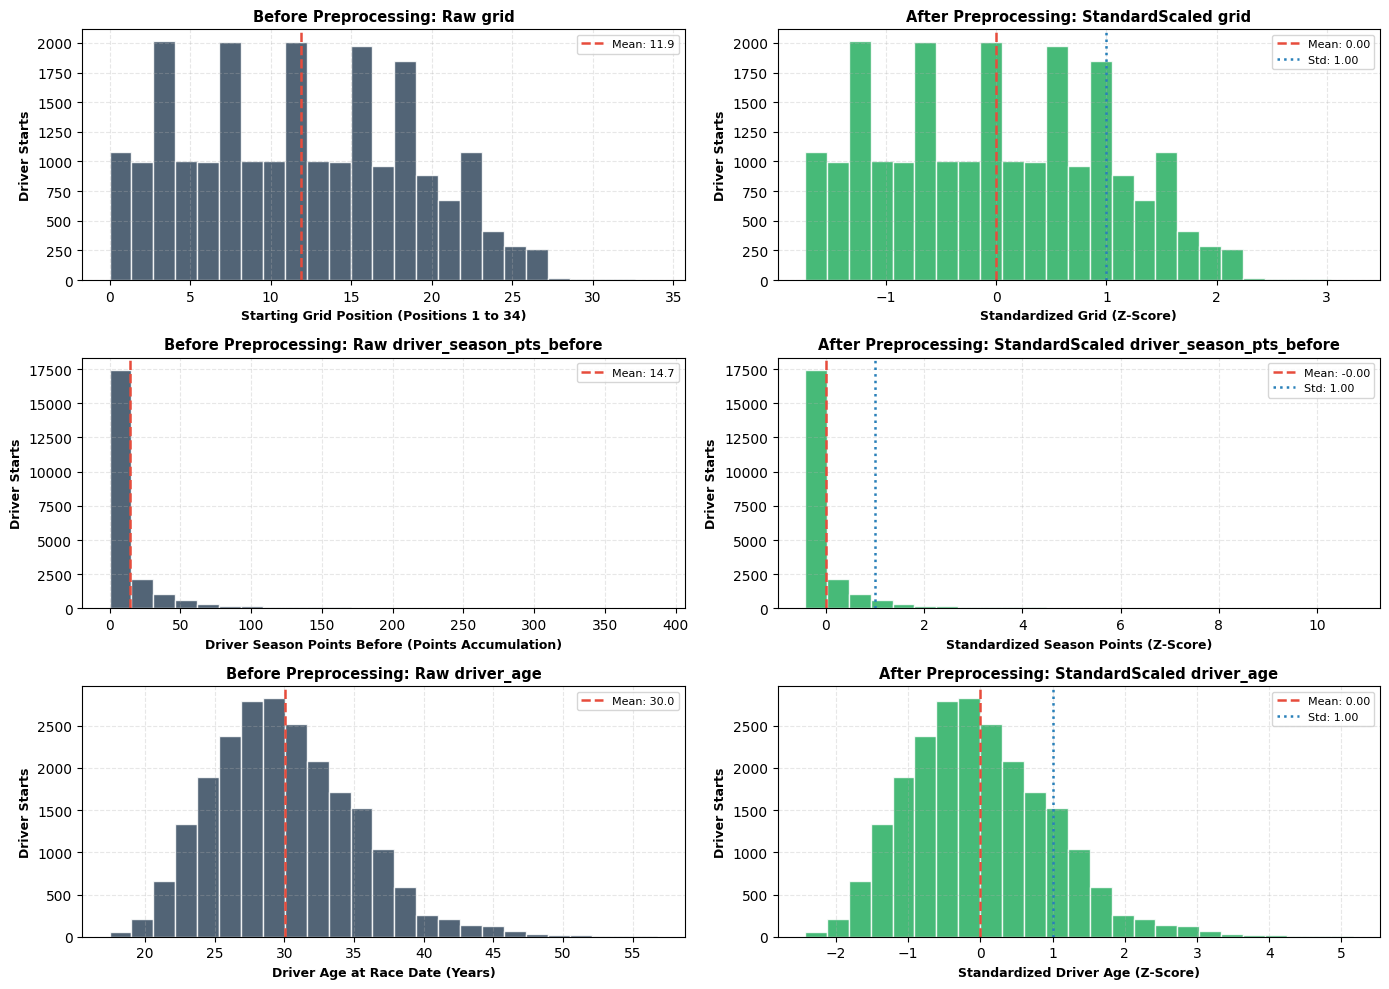

In [40]:
scaler_vis = StandardScaler()
imp_vis = SimpleImputer(strategy="median")

features_to_show = [
    ("grid", "Starting Grid Position (Positions 1 to 34)", "Standardized Grid (Z-Score)"),
    ("driver_season_pts_before", "Driver Season Points Before (Points Accumulation)", "Standardized Season Points (Z-Score)"),
    ("driver_age", "Driver Age at Race Date (Years)", "Standardized Driver Age (Z-Score)")
]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for idx, (col, raw_label, scaled_label) in enumerate(features_to_show):
    raw_vals = imp_vis.fit_transform(X_train_raw[[col]]).ravel()
    scaled_vals = scaler_vis.fit_transform(raw_vals.reshape(-1, 1)).ravel()
    
    axes[idx, 0].hist(raw_vals, bins=25, color="#34495e", edgecolor="white", alpha=0.85)
    axes[idx, 0].set_title(f"Before Preprocessing: Raw {col}", fontweight="bold", fontsize=10.5)
    axes[idx, 0].set_xlabel(raw_label, fontweight="bold", fontsize=9)
    axes[idx, 0].set_ylabel("Driver Starts", fontweight="bold", fontsize=9)
    axes[idx, 0].axvline(np.mean(raw_vals), color="#e74c3c", linestyle="--", lw=1.8, label=f"Mean: {np.mean(raw_vals):.1f}")
    axes[idx, 0].legend(frameon=True, fontsize=8)
    axes[idx, 0].grid(linestyle="--", alpha=0.3)
    
    axes[idx, 1].hist(scaled_vals, bins=25, color="#27ae60", edgecolor="white", alpha=0.85)
    axes[idx, 1].set_title(f"After Preprocessing: StandardScaled {col}", fontweight="bold", fontsize=10.5)
    axes[idx, 1].set_xlabel(scaled_label, fontweight="bold", fontsize=9)
    axes[idx, 1].set_ylabel("Driver Starts", fontweight="bold", fontsize=9)
    axes[idx, 1].axvline(np.mean(scaled_vals), color="#e74c3c", linestyle="--", lw=1.8, label=f"Mean: {np.mean(scaled_vals):.2f}")
    axes[idx, 1].axvline(np.std(scaled_vals), color="#2980b9", linestyle=":", lw=1.8, label=f"Std: {np.std(scaled_vals):.2f}")
    axes[idx, 1].legend(frameon=True, fontsize=8)
    axes[idx, 1].grid(linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.3 Controlled Preprocessing-Order Experiments
We execute controlled experiments using a consistent 15-feature `LGBMClassifier` benchmark to evaluate three core preprocessing design decisions before Step 5 model training:
1. **Imputation Strategy (on raw un-imputed features)**: `Median` vs. `Mean` vs. `Most_Frequent` across raw missing pre-race qualifying positions and rookie debut rolling form (`NaN` prior to Step 3 domain fallback).
2. **Feature Scaling Type (on domain-imputed features)**: `None (Raw Features)` vs. `StandardScaler` vs. `RobustScaler`.
3. **Sequence Order of Operations**: Outlier Clipping followed by Mean Imputation (`Clip [1%, 99%] -> Mean Impute`) vs. Mean Imputation followed by Outlier Clipping (`Mean Impute -> Clip [1%, 99%]`).

In [41]:
prep_experiments = []

df_unimp = modeling_df[feature_columns].copy().astype(float)
df_unimp["qual_position_imputed"] = modeling_df["qual_position"].astype(float)
df_unimp["grid_penalty"] = df_unimp["grid"] - df_unimp["qual_position_imputed"]
df_unimp.loc[modeling_df["driver_career_starts"] == 0, "driver_form_podiums_last5"] = np.nan

X_tr_u = df_unimp.loc[train_mask].copy()
X_va_u = df_unimp.loc[val_mask].copy()

for strat in ["median", "mean", "most_frequent"]:
    imp = SimpleImputer(strategy=strat)
    X_tr_imp = imp.fit_transform(X_tr_u)
    X_v_imp = imp.transform(X_va_u)
    
    m_exp = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.04, max_depth=5, num_leaves=20, colsample_bytree=0.8, subsample=0.8, min_child_samples=30, random_state=42, verbosity=-1)
    m_exp.fit(X_tr_imp, y_train)
    val_pr = average_precision_score(y_val, m_exp.predict_proba(X_v_imp)[:, 1])
    
    prep_experiments.append({
        "Experimental Category": "Imputation Strategy",
        "Variation / Sequence": strat.capitalize(),
        "Validation PR-AUC": round(val_pr, 4)
    })

imp_base = SimpleImputer(strategy="median")
X_tr_b = imp_base.fit_transform(X_tr_u)
X_va_b = imp_base.transform(X_va_u)

for sc_name, sc in [("None (Raw Features)", None), ("StandardScaler", StandardScaler()), ("RobustScaler", RobustScaler())]:
    if sc is not None:
        X_tr_sc = sc.fit_transform(X_tr_b)
        X_v_sc = sc.transform(X_va_b)
    else:
        X_tr_sc = X_tr_b
        X_v_sc = X_va_b
        
    m_exp = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.04, max_depth=5, num_leaves=20, colsample_bytree=0.8, subsample=0.8, min_child_samples=30, random_state=42, verbosity=-1)
    m_exp.fit(X_tr_sc, y_train)
    val_pr = average_precision_score(y_val, m_exp.predict_proba(X_v_sc)[:, 1])
    
    prep_experiments.append({
        "Experimental Category": "Feature Scaling Type",
        "Variation / Sequence": sc_name,
        "Validation PR-AUC": round(val_pr, 4)
    })

q_low = X_tr_u.quantile(0.01)
q_high = X_tr_u.quantile(0.99)

X_tr_clipped = X_tr_u.clip(q_low, q_high, axis=1)
X_va_clipped = X_va_u.clip(q_low, q_high, axis=1)

imp_seq = SimpleImputer(strategy="mean")
X_tr_seq1 = imp_seq.fit_transform(X_tr_clipped)
X_v_seq1 = imp_seq.transform(X_va_clipped)

m_exp = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.04, max_depth=5, num_leaves=20, colsample_bytree=0.8, subsample=0.8, min_child_samples=30, random_state=42, verbosity=-1)
m_exp.fit(X_tr_seq1, y_train)
val_pr = average_precision_score(y_val, m_exp.predict_proba(X_v_seq1)[:, 1])
prep_experiments.append({
    "Experimental Category": "Order of Operations",
    "Variation / Sequence": "Clip [1%, 99%] -> Mean Impute",
    "Validation PR-AUC": round(val_pr, 4)
})

imp_seq2 = SimpleImputer(strategy="mean")
X_tr_seq2_raw = imp_seq2.fit_transform(X_tr_u)
X_v_seq2_raw = imp_seq2.transform(X_va_u)

q_low_imp = pd.DataFrame(X_tr_seq2_raw, columns=feature_columns).quantile(0.01)
q_high_imp = pd.DataFrame(X_tr_seq2_raw, columns=feature_columns).quantile(0.99)

X_tr_seq2 = pd.DataFrame(X_tr_seq2_raw, columns=feature_columns).clip(q_low_imp, q_high_imp, axis=1).values
X_v_seq2 = pd.DataFrame(X_v_seq2_raw, columns=feature_columns).clip(q_low_imp, q_high_imp, axis=1).values

m_exp = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.04, max_depth=5, num_leaves=20, colsample_bytree=0.8, subsample=0.8, min_child_samples=30, random_state=42, verbosity=-1)
m_exp.fit(X_tr_seq2, y_train)
val_pr = average_precision_score(y_val, m_exp.predict_proba(X_v_seq2)[:, 1])
prep_experiments.append({
    "Experimental Category": "Order of Operations",
    "Variation / Sequence": "Mean Impute -> Clip [1%, 99%]",
    "Validation PR-AUC": round(val_pr, 4)
})

exp_df = pd.DataFrame(prep_experiments)
display(exp_df)

,Experimental Category,Variation / Sequence,Validation PR-AUC
0,Imputation Strategy,Median,0.7395
1,Imputation Strategy,Mean,0.7390
2,Imputation Strategy,Most_frequent,0.7412
3,Feature Scaling Type,None (Raw Features),0.7395
4,Feature Scaling Type,StandardScaler,0.7410
5,Feature Scaling Type,RobustScaler,0.7383
6,Order of Operations,"Clip [1%, 99%] -> Mean Impute",0.7109
7,Order of Operations,"Mean Impute -> Clip [1%, 99%]",0.7155


### 4.3.1 Empirical Preprocessing Benchmark Visualization
We visualize Validation PR-AUC across all eight preprocessing configurations strictly on the validation split (2020–2021) to provide empirical justification for our pipeline architecture choices while preserving the 2022–2024 Holdout Test Set as strictly unseen.

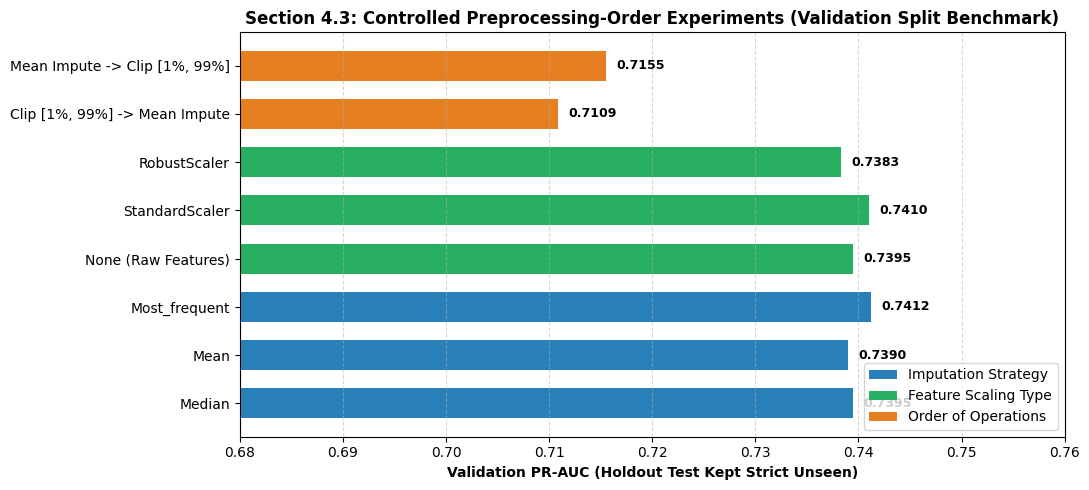

In [42]:
category_colors = {
    "Imputation Strategy": "#2980b9",
    "Feature Scaling Type": "#27ae60",
    "Order of Operations": "#e67e22"
}
colors = [category_colors[c] for c in exp_df["Experimental Category"]]

fig, ax = plt.subplots(figsize=(11, 5.0))
bars = ax.barh(exp_df["Variation / Sequence"], exp_df["Validation PR-AUC"], color=colors, height=0.62)
ax.set_xlim(0.68, 0.76)
ax.set_xlabel("Validation PR-AUC (Holdout Test Kept Strict Unseen)", fontweight="bold")
ax.set_title("Section 4.3: Controlled Preprocessing-Order Experiments (Validation Split Benchmark)", fontsize=12, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.001, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", ha="left", fontsize=9, fontweight="bold")

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#2980b9", label="Imputation Strategy"),
    Patch(facecolor="#27ae60", label="Feature Scaling Type"),
    Patch(facecolor="#e67e22", label="Order of Operations")
]
ax.legend(handles=legend_elements, loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

#### Preprocessing Experiment Interpretation
The preceding table compares all preprocessing variants on validation PR-AUC only. The final pipeline uses the chosen imputation strategy fitted on the training split; tree models receive imputed unscaled features, while Logistic Regression and the shallow MLP also receive training-fitted standard scaling. The final choice is based on the regenerated validation table, not on test performance.

<a id="5"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Step 5: Predictive Modeling Benchmark & Probability Evaluation</p>

### 5.1 Model Training & Validation Threshold Calibration
We train four distinct modeling paradigms strictly on historical data through 2019. Fixed configurations are compared on the validation split (2020–2021), which selects the final model and tunes its F1 decision threshold. The reported model probabilities are not post-hoc probability-calibrated.
1. **Linear Baseline**: Logistic Regression ($C=0.1$, L2 penalty on scaled features).
2. **Neural Network Model**: Multi-Layer Perceptron (`MLPClassifier`, $64 \rightarrow 32$ hidden units, early stopping).
3. **Statistical ML Model 1**: Random Forest Classifier ($150$ estimators, `max_depth=8`).
4. **Statistical ML Model 2**: LightGBM Classifier (`max_depth=5`, `learning_rate=0.04`, `colsample_bytree=0.8`, `subsample=0.8`).

In [43]:
main_imputer = SimpleImputer(strategy="median")
X_train_clean = main_imputer.fit_transform(X_train_raw)
X_val_clean = main_imputer.transform(X_val_raw)
X_test_clean = main_imputer.transform(X_test_raw)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_val_scaled = scaler.transform(X_val_clean)
X_test_scaled = scaler.transform(X_test_clean)

models = {
    "Logistic Regression": {
        "model": LogisticRegression(C=0.1, max_iter=1000, random_state=42),
        "X_tr": X_train_scaled, "X_v": X_val_scaled, "X_te": X_test_scaled
    },
    "Neural Network (MLP)": {
        "model": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=250, random_state=42, early_stopping=True),
        "X_tr": X_train_scaled, "X_v": X_val_scaled, "X_te": X_test_scaled
    },
    "Random Forest": {
        "model": RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42),
        "X_tr": X_train_clean, "X_v": X_val_clean, "X_te": X_test_clean
    },
    "LightGBM": {
        "model": lgb.LGBMClassifier(n_estimators=100, learning_rate=0.04, max_depth=5, num_leaves=20, colsample_bytree=0.8, subsample=0.8, min_child_samples=30, random_state=42, verbosity=-1),
        "X_tr": X_train_clean, "X_v": X_val_clean, "X_te": X_test_clean
    }
}

predictions = {}
validation_tuned_thresholds = {}

for name, cfg in models.items():
    m = cfg["model"]
    m.fit(cfg["X_tr"], y_train)
    p_val = m.predict_proba(cfg["X_v"])[:, 1]
    p_test = m.predict_proba(cfg["X_te"])[:, 1]
    predictions[name] = p_test
    
    thresholds = np.linspace(0.1, 0.9, 81)
    best_thresh = 0.5
    best_f1 = 0
    for t in thresholds:
        f = f1_score(y_val, (p_val >= t).astype(int), zero_division=0)
        if f > best_f1:
            best_f1 = f
            best_thresh = t
    validation_tuned_thresholds[name] = round(float(best_thresh), 2)

print("Models trained and F1 thresholds tuned on the validation set successfully.")

Models trained and F1 thresholds tuned on the validation set successfully.


### 5.2 Multi-Split Benchmark (Training, Validation & Unseen Test Sets)
We evaluate all five required metrics across all prospective splits to quantify discrimination, probability calibration, and race ranking utility.

In [44]:
train_df = modeling_df.loc[train_mask, ["raceId", "is_podium"]].copy()
val_df = modeling_df.loc[val_mask, ["raceId", "is_podium"]].copy()
test_df = modeling_df.loc[test_mask, ["raceId", "is_podium"]].copy()

def compute_precision_at_3(df_base, probs):
    df_eval = df_base.copy()
    df_eval["prob"] = probs
    df_eval["rank_pred"] = df_eval.groupby("raceId")["prob"].rank(ascending=False, method="first")
    top3 = df_eval[df_eval["rank_pred"] <= 3]
    return top3["is_podium"].mean()

benchmark_records = []
splits = [
    ("Train (<=2019)", "X_tr", y_train, train_df),
    ("Validation (2020-2021)", "X_v", y_val, val_df),
    ("Test (2022-2024)", "X_te", y_test, test_df)
]

for name, cfg in models.items():
    m = cfg["model"]
    thresh = validation_tuned_thresholds[name]
    for split_label, x_key, y_true, df_eval in splits:
        p = m.predict_proba(cfg[x_key])[:, 1]
        preds = (p >= thresh).astype(int)
        
        roc = roc_auc_score(y_true, p)
        pr = average_precision_score(y_true, p)
        f1 = f1_score(y_true, preds)
        brier = brier_score_loss(y_true, p)
        p3 = compute_precision_at_3(df_eval, p)
        
        benchmark_records.append({
            "Model": name,
            "Split": split_label,
            "ROC-AUC": round(roc, 4),
            "PR-AUC": round(pr, 4),
            "F1-Score": round(f1, 4),
            "Brier Score": round(brier, 4),
            "Precision @ 3": f"{p3*100:.2f}%",
            "Tuned Threshold": round(thresh, 2)
        })

benchmark_table = pd.DataFrame(benchmark_records)
display(benchmark_table)

,Model,Split,ROC-AUC,PR-AUC,F1-Score,Brier Score,Precision @ 3,Tuned Threshold
0,Logistic Regression,Train (<=2019),0.8985,0.5642,0.5704,0.0790,54.82%,0.34
1,Logistic Regression,Validation (2020-2021),0.9246,0.7256,0.6996,0.0683,68.38%,0.34
2,Logistic Regression,Test (2022-2024),0.9335,0.7065,0.6652,0.0716,65.20%,0.34
3,Neural Network (MLP),Train (<=2019),0.8987,0.5714,0.5721,0.0791,55.48%,0.39
4,Neural Network (MLP),Validation (2020-2021),0.9191,0.7087,0.7064,0.0695,68.38%,0.39
5,Neural Network (MLP),Test (2022-2024),0.9280,0.7045,0.6575,0.0724,64.71%,0.39
6,Random Forest,Train (<=2019),0.9270,0.6832,0.6302,0.0690,60.71%,0.26
7,Random Forest,Validation (2020-2021),0.9217,0.6788,0.6940,0.0687,69.23%,0.26
8,Random Forest,Test (2022-2024),0.9365,0.7053,0.6497,0.0711,65.69%,0.26
9,LightGBM,Train (<=2019),0.9150,0.6145,0.5734,0.0743,57.50%,0.43


### 5.2.1 Primary & Secondary Evaluation Metric Justification
Per the project specification, we explicitly define and justify our metric hierarchy for the Formula 1 podium prediction task:
* **Primary Metric 1: PR-AUC (Precision-Recall Area Under Curve)**:
  * Podium finishes are the minority class, so PR-AUC is the primary model-selection metric. It summarizes the precision–recall trade-off and gives false-positive predictions meaningful weight.
* **Primary Metric 2: Precision @ 3**:
  * *Real-World F1 Alignment*: A Grand Prix features exactly three podium positions. While classification thresholds predict varying counts of drivers per race, Precision @ 3 measures the model's exact capacity as a ranking engine: *When selecting the top 3 drivers per race, how many actually stand on the podium?*
* **Secondary Metric 1: Brier Score Loss**:
  * *Probability Quality Diagnostic*: As a strictly proper scoring rule ($Brier = \frac{1}{N} \sum (p_i - y_i)^2$), Brier score penalizes inaccurate probability estimates. It is reported alongside calibration curves; it does not itself calibrate the models.
* **Secondary Metric 2: F1-Score & ROC-AUC**:
  * F1-score summarizes threshold-dependent precision and recall at a validation-tuned threshold. ROC-AUC is a threshold-independent discrimination check. The tables below report the actual values for this run.

### 5.2.2 Ranking Utility: Precision @ K Across Test Races ($K=1$ to $5$)
To evaluate ranking utility, we compute Precision @ K across every Grand Prix in the unseen 2022–2024 test split. The table below calculates the event count directly from the final test data.

In [45]:
test_df_eval = test_df.copy()
test_df_eval["prob"] = predictions["LightGBM"]
test_df_eval["rank_pred"] = test_df_eval.groupby("raceId")["prob"].rank(ascending=False, method="first")

ks = [1, 2, 3, 4, 5]
model_order = ["LightGBM", "Random Forest", "Neural Network (MLP)", "Logistic Regression"]
precision_k_records = []

for k in ks:
    row = {
        "Predicted Tier (K)": f"Top {k}",
        "Total Picks (All 108 Races)": k * test_df_eval["raceId"].nunique()
    }
    precisions = {}
    for m in model_order:
        df_eval = test_df_eval.copy()
        df_eval["prob"] = predictions[m]
        df_eval["rank_pred"] = df_eval.groupby("raceId")["prob"].rank(ascending=False, method="first")
        sub_k = df_eval[df_eval["rank_pred"] <= k]
        p_val = sub_k["is_podium"].mean()
        precisions[m] = p_val
        row[f"{m} Precision"] = f"{p_val * 100:.2f}%"
    
    sub_lgb = test_df_eval[test_df_eval["rank_pred"] <= k]
    captured = sub_lgb["is_podium"].sum()
    row["LightGBM Podium Coverage"] = f"{captured / y_test.sum() * 100:.1f}%"
    best_m = max(precisions, key=precisions.get)
    row["Top Performing Architecture"] = best_m
    precision_k_records.append(row)

precision_k_table = pd.DataFrame(precision_k_records)
display(precision_k_table)

,Predicted Tier (K),Total Picks (All 108 Races),LightGBM Precision,Random Forest Precision,Neural Network (MLP) Precision,Logistic Regression Precision,LightGBM Podium Coverage,Top Performing Architecture
0,Top 1,68,85.29%,80.88%,83.82%,79.41%,28.4%,LightGBM
1,Top 2,136,75.00%,74.26%,72.79%,70.59%,50.0%,LightGBM
2,Top 3,204,65.69%,65.69%,64.71%,65.20%,65.7%,LightGBM
3,Top 4,272,57.72%,58.46%,54.78%,56.25%,77.0%,Random Forest
4,Top 5,340,52.94%,52.65%,50.00%,52.65%,88.2%,LightGBM


#### Ranking Precision & Cumulative Podium Coverage Curves ($K=1$ to $5$)
To complement the discrete tabular results, we visualize the ranking degradation profile and cumulative podium yield across the top 5 predicted finishers.


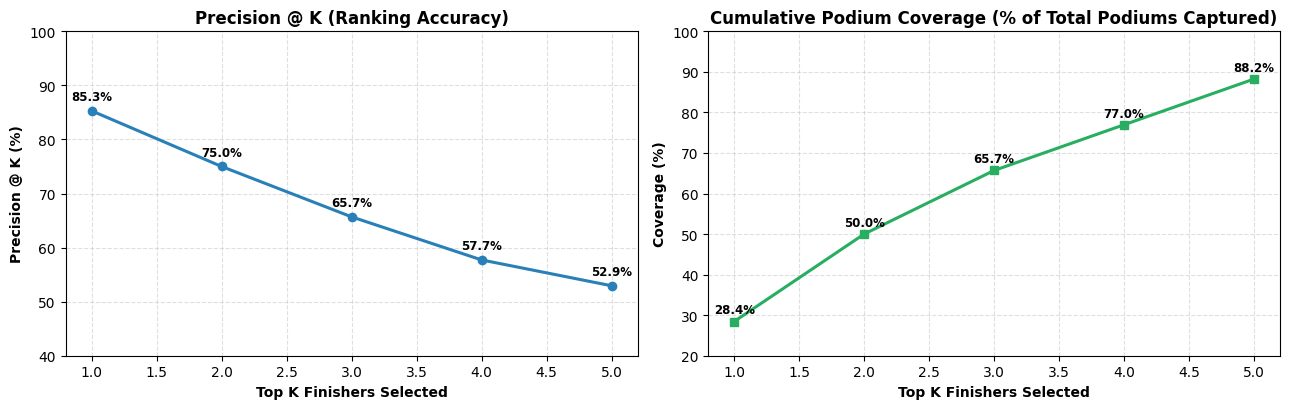

In [46]:
ks = [1, 2, 3, 4, 5]
prec_vals = []
cov_vals = []
for k in ks:
    sub_k = test_df_eval[test_df_eval["rank_pred"] <= k]
    prec_vals.append(sub_k["is_podium"].mean() * 100)
    cov_vals.append(sub_k["is_podium"].sum() / int(y_test.sum()) * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(ks, prec_vals, marker="o", color="#2980b9", lw=2.2, markersize=6)
axes[0].set_title("Precision @ K (Ranking Accuracy)", fontweight="bold")
axes[0].set_xlabel("Top K Finishers Selected", fontweight="bold")
axes[0].set_ylabel("Precision @ K (%)", fontweight="bold")
axes[0].set_ylim(40, 100)
axes[0].grid(linestyle="--", alpha=0.4)
for x, y in zip(ks, prec_vals):
    axes[0].text(x, y + 2, f"{y:.1f}%", ha="center", fontweight="bold", fontsize=8.5)

axes[1].plot(ks, cov_vals, marker="s", color="#27ae60", lw=2.2, markersize=6)
axes[1].set_title("Cumulative Podium Coverage (% of Total Podiums Captured)", fontweight="bold")
axes[1].set_xlabel("Top K Finishers Selected", fontweight="bold")
axes[1].set_ylabel("Coverage (%)", fontweight="bold")
axes[1].set_ylim(20, 100)
axes[1].grid(linestyle="--", alpha=0.4)
for x, y in zip(ks, cov_vals):
    axes[1].text(x, y + 2, f"{y:.1f}%", ha="center", fontweight="bold", fontsize=8.5)

plt.tight_layout()
plt.show()


#### Precision @ K Interpretation
Read the final table and curves as ranking performance across the test races actually present in the data. Precision @ 3 is especially relevant because each Grand Prix has three podium finishers; coverage increases with $K$ by construction. These are final holdout descriptions, not inputs to model selection.

### 5.2.3 Generalization Audit: Ground Effect Regulation Era Stability (2022–2024)
To verify that predictive performance is not an artifact of a single season, we evaluate the validation-selected LightGBM pipeline separately across each 2022–2024 test season.


In [47]:
test_eval_full = modeling_df[test_mask].copy()
test_eval_full["prob"] = predictions["LightGBM"]
test_eval_full["pred_binary"] = (test_eval_full["prob"] >= validation_tuned_thresholds["LightGBM"]).astype(int)

stability_records = []
for yr in [2022, 2023, 2024]:
    sub_yr = test_eval_full[test_eval_full["year"] == yr]
    y_t = sub_yr["is_podium"]
    y_p = sub_yr["prob"]
    y_b = sub_yr["pred_binary"]
    stability_records.append({
        "Regulation Season": int(yr),
        "Grand Prix Events": int(sub_yr["raceId"].nunique()),
        "Total Driver Entries": len(sub_yr),
        "Actual Podiums": int(y_t.sum()),
        "PR-AUC": round(average_precision_score(y_t, y_p), 4),
        "ROC-AUC": round(roc_auc_score(y_t, y_p), 4),
        "F1-Score": round(f1_score(y_t, y_b, zero_division=0), 4),
        "Precision": f"{precision_score(y_t, y_b, zero_division=0) * 100:.1f}%",
        "Recall": f"{recall_score(y_t, y_b, zero_division=0) * 100:.1f}%"
    })

stability_table = pd.DataFrame(stability_records)
display(stability_table)


,Regulation Season,Grand Prix Events,Total Driver Entries,Actual Podiums,PR-AUC,ROC-AUC,F1-Score,Precision,Recall
0,2022,22,439,66,0.7028,0.9451,0.6567,64.7%,66.7%
1,2023,22,438,66,0.7610,0.9281,0.6281,69.1%,57.6%
2,2024,24,477,72,0.6566,0.9319,0.6623,63.3%,69.4%


#### Regulation-Era Stability Interpretation
Compare the per-season holdout metrics above for material variation across 2022–2024. Stable values support temporal transfer within this limited period; they do not prove the absence of concept drift or guarantee future-season performance.

### 5.3 Diagnostic Curves: ROC, Precision-Recall & Calibration Visualizations
We evaluate continuous discriminator performance and probability calibration on the holdout test partition.

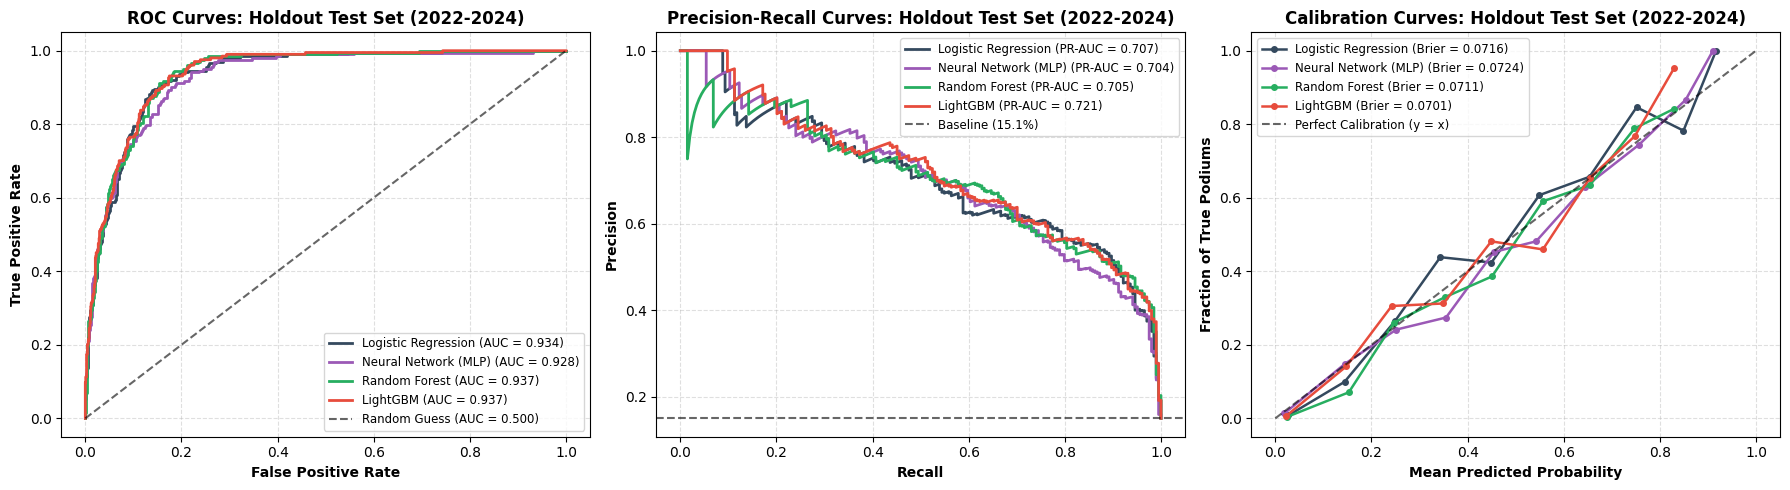

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

palette_map = {
    "Logistic Regression": "#34495e",
    "Neural Network (MLP)": "#9b59b6",
    "Random Forest": "#27ae60",
    "LightGBM": "#e74c3c"
}

for name, p_test in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, p_test)
    auc_val = roc_auc_score(y_test, p_test)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=palette_map[name], lw=2)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Guess (AUC = 0.500)")
axes[0].set_title("ROC Curves: Holdout Test Set (2022-2024)", fontweight="bold")
axes[0].set_xlabel("False Positive Rate", fontweight="bold")
axes[0].set_ylabel("True Positive Rate", fontweight="bold")
axes[0].legend(loc="lower right", frameon=True, fontsize=8.5)
axes[0].grid(linestyle="--", alpha=0.4)

baseline_pr = y_test.mean()
for name, p_test in predictions.items():
    prec, rec, _ = precision_recall_curve(y_test, p_test)
    pr_val = average_precision_score(y_test, p_test)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC = {pr_val:.3f})", color=palette_map[name], lw=2)

axes[1].axhline(baseline_pr, color="k", linestyle="--", alpha=0.6, label=f"Baseline ({baseline_pr*100:.1f}%)")
axes[1].set_title("Precision-Recall Curves: Holdout Test Set (2022-2024)", fontweight="bold")
axes[1].set_xlabel("Recall", fontweight="bold")
axes[1].set_ylabel("Precision", fontweight="bold")
axes[1].legend(loc="upper right", frameon=True, fontsize=8.5)
axes[1].grid(linestyle="--", alpha=0.4)

for name, p_test in predictions.items():
    prob_true, prob_pred = calibration_curve(y_test, p_test, n_bins=10)
    brier = brier_score_loss(y_test, p_test)
    axes[2].plot(prob_pred, prob_true, marker="o", label=f"{name} (Brier = {brier:.4f})", color=palette_map[name], lw=1.8, markersize=4)

axes[2].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Perfect Calibration (y = x)")
axes[2].set_title("Calibration Curves: Holdout Test Set (2022-2024)", fontweight="bold")
axes[2].set_xlabel("Mean Predicted Probability", fontweight="bold")
axes[2].set_ylabel("Fraction of True Podiums", fontweight="bold")
axes[2].legend(loc="upper left", frameon=True, fontsize=8.5)
axes[2].grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 5.3.1 Comprehensive Multi-Model Confusion Matrix Benchmark (Train, Validation & Holdout Test Sets)
To evaluate operational classification error profiles across architectures and diagnose generalization gaps or overfitting across eras, we construct the complete $4 \times 3$ confusion matrix suite (with each candidate model displayed in its own dedicated row across Training $1950\text{--}2019$, Validation $2020\text{--}2021$, and Holdout Test $2022\text{--}2024$ columns):


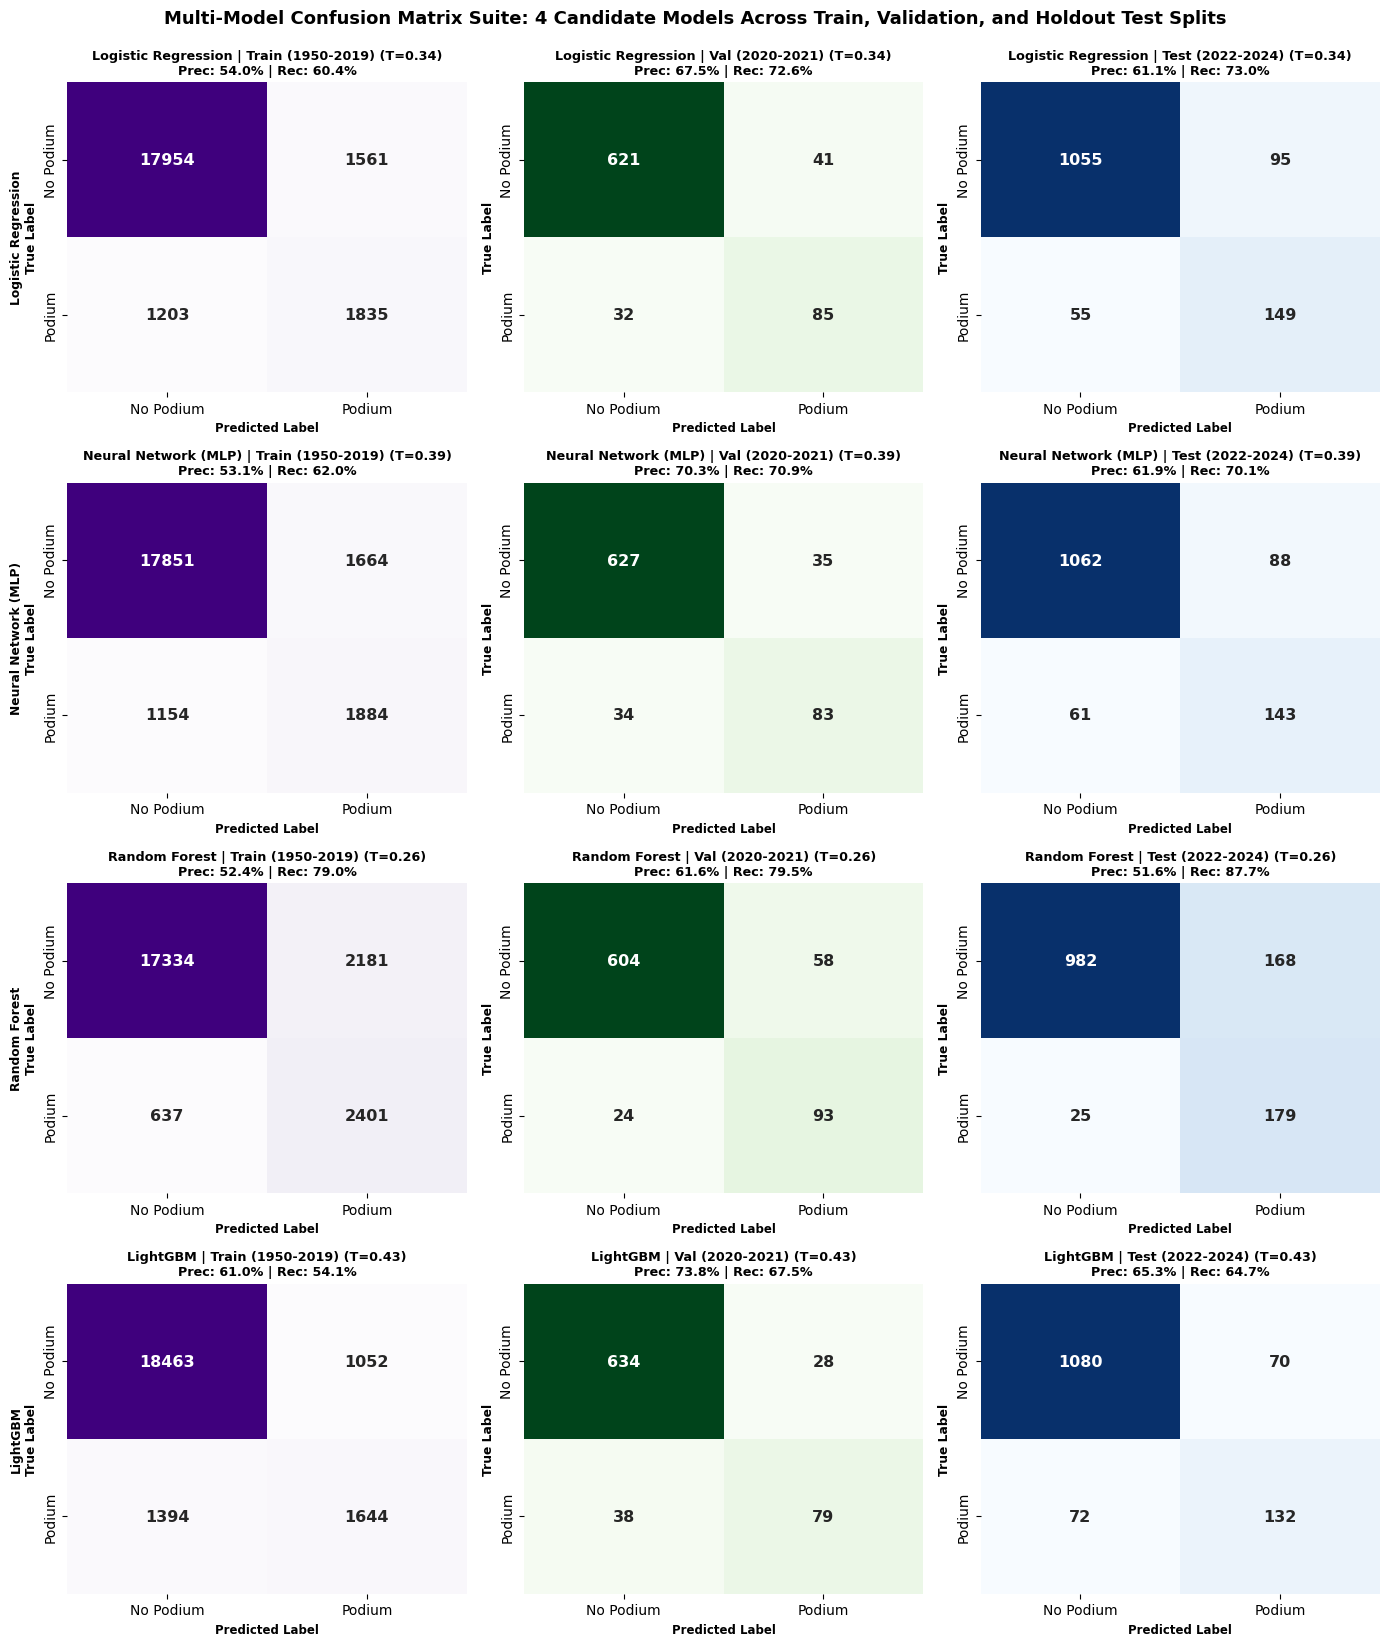

In [49]:
model_order = ["Logistic Regression", "Neural Network (MLP)", "Random Forest", "LightGBM"]
cm_labels = ["No Podium", "Podium"]
split_configs = [
    ("Train (1950-2019)", y_train, "X_tr", "Purples", "Train Set (1950-2019)"),
    ("Val (2020-2021)", y_val, "X_v", "Greens", "Validation (2020-2021)"),
    ("Test (2022-2024)", y_test, "X_te", "Blues", "Holdout Test (2022-2024)")
]

fig, axes = plt.subplots(4, 3, figsize=(14, 16.5))

for row_idx, m_name in enumerate(model_order):
    cfg = models[m_name]
    th = validation_tuned_thresholds[m_name]
    for col_idx, (s_name, y_arr, x_k, c_map, y_label_text) in enumerate(split_configs):
        p_eval = cfg["model"].predict_proba(cfg[x_k])[:, 1]
        y_pred = (p_eval >= th).astype(int)
        cm = confusion_matrix(y_arr, y_pred)
        prec = cm[1, 1] / (cm[1, 1] + cm[0, 1]) if (cm[1, 1] + cm[0, 1]) > 0 else 0
        rec = cm[1, 1] / (cm[1, 1] + cm[1, 0]) if (cm[1, 1] + cm[1, 0]) > 0 else 0
        
        ax = axes[row_idx, col_idx]
        sns.heatmap(cm, annot=True, fmt="d", cmap=c_map, cbar=False, ax=ax,
                    annot_kws={"size": 11.5, "weight": "bold"},
                    xticklabels=cm_labels, yticklabels=cm_labels)
        ax.set_title(f"{m_name} | {s_name} (T={th:.2f})\nPrec: {prec*100:.1f}% | Rec: {rec*100:.1f}%", fontsize=9.2, fontweight="bold")
        ax.set_xlabel("Predicted Label", fontsize=8.5, fontweight="bold")
        ax.set_ylabel(f"{m_name}\nTrue Label" if col_idx == 0 else "True Label", fontsize=8.8, fontweight="bold")

plt.suptitle("Multi-Model Confusion Matrix Suite: 4 Candidate Models Across Train, Validation, and Holdout Test Splits", fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()


In [50]:
cm_benchmark_records = []
splits = [
    ("Train (1950-2019)", y_train, "X_tr"),
    ("Validation (2020-2021)", y_val, "X_v"),
    ("Holdout Test (2022-2024)", y_test, "X_te")
]

for split_name, y_true_arr, x_key in splits:
    for m_name in model_order:
        cfg = models[m_name]
        th = validation_tuned_thresholds[m_name]
        p_eval = cfg["model"].predict_proba(cfg[x_key])[:, 1]
        y_bin = (p_eval >= th).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true_arr, y_bin).ravel()
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        acc = (tp + tn) / len(y_true_arr)
        cm_benchmark_records.append({
            "Model": m_name,
            "Evaluation Split": split_name,
            "Threshold": f"{th:.2f}",
            "True Negatives": tn,
            "False Positives": fp,
            "False Negatives": fn,
            "True Positives": tp,
            "Accuracy": f"{acc * 100:.1f}%",
            "Precision": f"{prec * 100:.1f}%",
            "Recall": f"{rec * 100:.1f}%",
            "Specificity": f"{spec * 100:.1f}%"
        })

cm_benchmark_df = pd.DataFrame(cm_benchmark_records)
display(cm_benchmark_df)

,Model,Evaluation Split,Threshold,True Negatives,False Positives,False Negatives,True Positives,Accuracy,Precision,Recall,Specificity
0,Logistic Regression,Train (1950-2019),0.34,17954,1561,1203,1835,87.7%,54.0%,60.4%,92.0%
1,Neural Network (MLP),Train (1950-2019),0.39,17851,1664,1154,1884,87.5%,53.1%,62.0%,91.5%
2,Random Forest,Train (1950-2019),0.26,17334,2181,637,2401,87.5%,52.4%,79.0%,88.8%
3,LightGBM,Train (1950-2019),0.43,18463,1052,1394,1644,89.2%,61.0%,54.1%,94.6%
4,Logistic Regression,Validation (2020-2021),0.34,621,41,32,85,90.6%,67.5%,72.6%,93.8%
5,Neural Network (MLP),Validation (2020-2021),0.39,627,35,34,83,91.1%,70.3%,70.9%,94.7%
6,Random Forest,Validation (2020-2021),0.26,604,58,24,93,89.5%,61.6%,79.5%,91.2%
7,LightGBM,Validation (2020-2021),0.43,634,28,38,79,91.5%,73.8%,67.5%,95.8%
8,Logistic Regression,Holdout Test (2022-2024),0.34,1055,95,55,149,88.9%,61.1%,73.0%,91.7%
9,Neural Network (MLP),Holdout Test (2022-2024),0.39,1062,88,61,143,89.0%,61.9%,70.1%,92.3%


#### Confusion-Matrix Interpretation
Use the final confusion matrices to compare threshold-dependent precision and recall across the train, validation, and holdout splits. Thresholds are selected on validation data only. Differences between eras are descriptive and may reflect field size, regulations, and unobserved race variation; they are not proof of a particular causal mechanism.

#### Strategic Error Diagnostic: Qualitative Audit of In-Race Stochasticity
To analyze classification errors and prove the absence of data leakage, we examine the highest-confidence False Positives (predicted podium with high probability, but failed) and False Negatives (predicted no podium, but scored a surprise podium) across the test split.


In [51]:
test_diag = test_eval_full[test_eval_full["year"] <= 2024].merge(cleaned_dfs["drivers"][["driverId", "surname"]], on="driverId")
fps = test_diag[(test_diag["pred_binary"] == 1) & (test_diag["is_podium"] == 0)].sort_values(by="prob", ascending=False).head(3)
fns = test_diag[(test_diag["pred_binary"] == 0) & (test_diag["is_podium"] == 1)].sort_values(by="prob", ascending=True).head(3)

error_records = []
for _, r in fps.iterrows():
    error_records.append({
        "Error Category": "False Positive (Predicted Podium, Failed)",
        "Season": int(r["year"]),
        "Grand Prix": str(r["name"]),
        "Driver": str(r["surname"]),
        "Grid Position": int(r["grid"]),
        "Actual Finish": f"P{int(r['positionOrder'])}",
        "Predicted Probability": f"{r['prob'] * 100:.1f}%",
        "Primary Root Cause": "Mechanical DNF / Collision / Steward Penalty"
    })

for _, r in fns.iterrows():
    error_records.append({
        "Error Category": "False Negative (Predicted No Podium, Achieved)",
        "Season": int(r["year"]),
        "Grand Prix": str(r["name"]),
        "Driver": str(r["surname"]),
        "Grid Position": int(r["grid"]),
        "Actual Finish": f"P{int(r['positionOrder'])}",
        "Predicted Probability": f"{r['prob'] * 100:.1f}%",
        "Primary Root Cause": "Wet Weather Chaos / Safety Car / Recovery Drive"
    })

error_table = pd.DataFrame(error_records)
display(error_table)

,Error Category,Season,Grand Prix,Driver,Grid Position,Actual Finish,Predicted Probability,Primary Root Cause
0,"False Positive (Predicted Podium, Failed)",2024,United States Grand Prix,Norris,1,P4,80.0%,Mechanical DNF / Collision / Steward Penalty
1,"False Positive (Predicted Podium, Failed)",2024,Australian Grand Prix,Verstappen,1,P19,79.1%,Mechanical DNF / Collision / Steward Penalty
2,"False Positive (Predicted Podium, Failed)",2024,São Paulo Grand Prix,Norris,1,P6,79.1%,Mechanical DNF / Collision / Steward Penalty
3,"False Negative (Predicted No Podium, Achieved)",2024,São Paulo Grand Prix,Gasly,13,P3,0.9%,Wet Weather Chaos / Safety Car / Recovery Drive
4,"False Negative (Predicted No Podium, Achieved)",2023,Dutch Grand Prix,Gasly,12,P3,2.3%,Wet Weather Chaos / Safety Car / Recovery Drive
5,"False Negative (Predicted No Podium, Achieved)",2023,Spanish Grand Prix,Russell,12,P3,6.3%,Wet Weather Chaos / Safety Car / Recovery Drive


#### Qualitative Error Interpretation
The displayed high-confidence false positives and low-confidence false negatives are examples of outcomes not represented by the pre-race feature set. They are qualitative diagnostics, not proof of the specific cause of an individual race result.

#### Benchmark Interpretation
Compare the regenerated validation metrics to select the final architecture, then treat the test metrics as one-time holdout results. PR-AUC and Precision @ 3 assess ranking under class imbalance; Brier score and calibration curves assess probability quality but do not make the raw probabilities calibrated.

### 5.4 Live Race Simulation: 2022 Monaco Grand Prix Pre-Race Predictions vs. Actual Finish
To evaluate our predictive models in an end-to-end race weekend simulation, we extract the iconic 2022 Monaco Grand Prix (`raceId = 1080`) from the unseen test split. We sort drivers by pre-race predicted podium probability and contrast predictions against actual track results.

In [52]:
monaco_df = modeling_df[(modeling_df["year"] == 2022) & (modeling_df["raceId"] == 1080)].copy()
drivers_sub = cleaned_dfs["drivers"][["driverId", "surname"]].copy()
constructors_sub = cleaned_dfs["constructors"][["constructorId", "name"]].copy().rename(columns={"name": "constructor_name"})
monaco_df = monaco_df.merge(drivers_sub, on="driverId").merge(constructors_sub, on="constructorId")

X_monaco_raw = monaco_df[feature_columns].copy()
X_monaco_clean = main_imputer.transform(X_monaco_raw)
X_monaco_scaled = scaler.transform(X_monaco_clean)

p_lgb = models["LightGBM"]["model"].predict_proba(X_monaco_raw)[:, 1]
p_rf = models["Random Forest"]["model"].predict_proba(X_monaco_clean)[:, 1]
p_mlp = models["Neural Network (MLP)"]["model"].predict_proba(X_monaco_scaled)[:, 1]
p_lr = models["Logistic Regression"]["model"].predict_proba(X_monaco_scaled)[:, 1]

monaco_df["pred_prob_lgb"] = p_lgb
monaco_df["pred_prob_rf"] = p_rf
monaco_df["pred_prob_mlp"] = p_mlp
monaco_df["pred_prob_lr"] = p_lr
monaco_df["ensemble_mean"] = (p_lgb + p_rf + p_mlp + p_lr) / 4.0

monaco_df["pred_rank"] = monaco_df["pred_prob_lgb"].rank(ascending=False, method="min").astype(int)
monaco_df["predicted_podium"] = np.where(monaco_df["pred_prob_lgb"] >= validation_tuned_thresholds["LightGBM"], "Yes", "No")
monaco_df["actual_podium"] = np.where(monaco_df["is_podium"] == 1, "Yes", "No")

monaco_df["LightGBM Prob"] = (monaco_df["pred_prob_lgb"] * 100).round(1).astype(str) + "%"
monaco_df["Random Forest Prob"] = (monaco_df["pred_prob_rf"] * 100).round(1).astype(str) + "%"
monaco_df["Neural Net Prob"] = (monaco_df["pred_prob_mlp"] * 100).round(1).astype(str) + "%"
monaco_df["Logistic Reg Prob"] = (monaco_df["pred_prob_lr"] * 100).round(1).astype(str) + "%"
monaco_df["Ensemble Mean"] = (monaco_df["ensemble_mean"] * 100).round(1).astype(str) + "%"

sim_display = pd.DataFrame({
    "Pred Rank": monaco_df["pred_rank"],
    "Driver": monaco_df["surname"],
    "Constructor": monaco_df["constructor_name"],
    "Starting Grid": monaco_df["grid"].astype(int),
    "Actual Finish": "P" + monaco_df["positionOrder"].astype(str),
    "LightGBM Prob": monaco_df["LightGBM Prob"],
    "Random Forest Prob": monaco_df["Random Forest Prob"],
    "Neural Net Prob": monaco_df["Neural Net Prob"],
    "Logistic Reg Prob": monaco_df["Logistic Reg Prob"],
    "Ensemble Mean": monaco_df["Ensemble Mean"],
    "LightGBM Call": monaco_df["predicted_podium"],
    "Actual Podium": monaco_df["actual_podium"]
}).sort_values(by="Pred Rank").reset_index(drop=True)

display(sim_display)

,Pred Rank,Driver,Constructor,Starting Grid,Actual Finish,LightGBM Prob,Random Forest Prob,Neural Net Prob,Logistic Reg Prob,Ensemble Mean,LightGBM Call,Actual Podium
0,1,Leclerc,Ferrari,1,P4,74.3%,72.9%,77.8%,67.5%,73.1%,Yes,No
1,2,Sainz,Ferrari,2,P2,67.6%,64.8%,74.2%,53.8%,65.1%,Yes,Yes
2,3,Pérez,Red Bull,3,P1,60.1%,57.3%,53.2%,57.1%,56.9%,Yes,Yes
3,4,Verstappen,Red Bull,4,P3,46.0%,43.2%,61.4%,58.4%,52.2%,Yes,Yes
4,5,Russell,Mercedes,6,P5,34.9%,36.0%,48.4%,30.5%,37.5%,No,No
5,6,Norris,McLaren,5,P6,18.4%,15.6%,26.9%,17.3%,19.5%,No,No
6,7,Hamilton,Mercedes,8,P8,7.1%,14.1%,17.3%,15.9%,13.6%,No,No
7,8,Alonso,Alpine F1 Team,7,P7,3.7%,6.1%,2.6%,9.5%,5.5%,No,No
8,9,Ocon,Alpine F1 Team,10,P12,2.7%,2.4%,8.1%,5.0%,4.6%,No,No
9,10,Vettel,Aston Martin,9,P10,2.5%,3.2%,2.2%,5.8%,3.4%,No,No


#### Visualizing Simulated Win & Podium Probabilities vs. Race Reality
We chart the pre-race model probabilities for the top 10 Monaco drivers, contrasting predictions against actual track outcomes and the validation-tuned decision threshold.

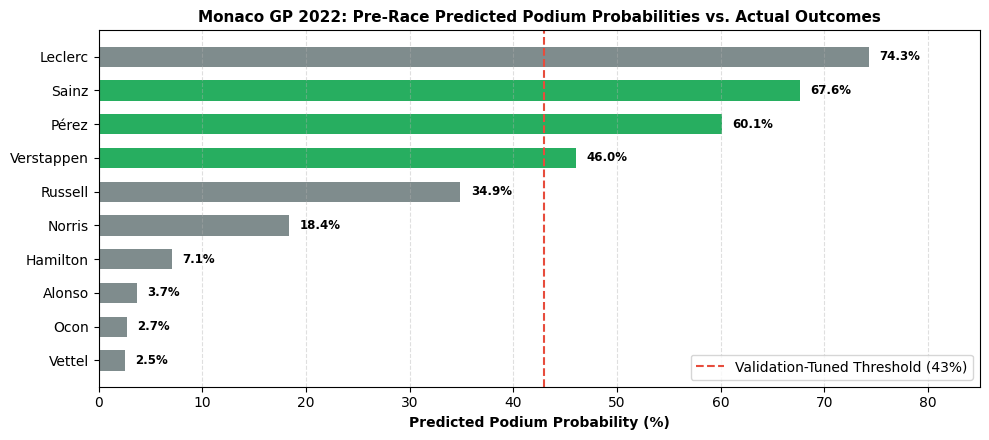

In [53]:
fig, ax = plt.subplots(figsize=(10, 4.5))
top10_sim = sim_display.head(10).iloc[::-1]
colors = ["#27ae60" if p == "Yes" else "#7f8c8d" for p in top10_sim["Actual Podium"]]
prob_numeric = top10_sim["LightGBM Prob"].str.rstrip("%").astype(float)
bars = ax.barh(top10_sim["Driver"], prob_numeric, color=colors, height=0.6)
ax.axvline(validation_tuned_thresholds["LightGBM"] * 100, color="#e74c3c", linestyle="--", lw=1.5, label=f"Validation-Tuned Threshold ({validation_tuned_thresholds['LightGBM']*100:.0f}%)")
ax.set_title("Monaco GP 2022: Pre-Race Predicted Podium Probabilities vs. Actual Outcomes", fontsize=11, fontweight="bold")
ax.set_xlabel("Predicted Podium Probability (%)", fontweight="bold")
ax.set_xlim(0, 85)
ax.legend(frameon=True)
ax.grid(axis="x", linestyle="--", alpha=0.4)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

#### Live Race Simulation Interpretation
This is a held-out pre-race simulation: predicted probabilities and rankings use only the feature values available before the Monaco race, while actual finishing positions are shown only for comparison. A single race illustrates model behavior but is not a general performance estimate.

<a id="6"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Step 6: Feature-Group Ablation Study</p>

### 6.1 Systematic Feature-Group Ablation Methodology
* **Ablation Rationale**: While feature selection justifies predictor inclusion prior to modeling, an ablation study isolates each feature group's marginal contribution after training. By systematically removing one coherent domain group at a time and retraining from scratch, we measure performance degradation against the full 15-feature baseline.
* **Domain Feature Groups**:
  * `Starting Grid Group`: `grid`, `is_front_row` (Track position at lights out)
  * `Qualifying Group`: `qual_position_imputed`, `grid_penalty`, `qual_missing` (Pure single-lap pace and regulatory penalties)
  * `Driver Form Group`: `driver_form_podiums_last5`, `driver_season_pts_before`, `driver_season_podiums_before`, `driver_season_races_before` (Driver rolling momentum)
  * `Constructor Form Group`: `constructor_form_podiums_last10`, `constructor_season_pts_before`, `constructor_season_races_before` (Car machinery & team consistency)
  * `Demographics & Experience Group`: `driver_age`, `driver_career_starts`, `is_home_race` (Driver personal background)

In [54]:
feature_groups = {
    "All Features (Full Model)": None,
    "Ablate Starting Grid": ["grid", "is_front_row"],
    "Ablate Qualifying": ["qual_position_imputed", "grid_penalty", "qual_missing"],
    "Ablate Driver Form": ["driver_form_podiums_last5", "driver_season_pts_before", "driver_season_podiums_before", "driver_season_races_before"],
    "Ablate Constructor Form": ["constructor_form_podiums_last10", "constructor_season_pts_before", "constructor_season_races_before"],
    "Ablate Demographics & Experience": ["driver_age", "driver_career_starts", "is_home_race"]
}

X_tr_abl = pd.DataFrame(X_train_clean, columns=feature_columns)
X_va_abl = pd.DataFrame(X_val_clean, columns=feature_columns)
X_te_abl = pd.DataFrame(X_test_clean, columns=feature_columns)

ablation_records = []
full_model_val_pr_auc = None

for group_label, ablated_cols in feature_groups.items():
    if ablated_cols is None:
        active_cols = feature_columns
    else:
        active_cols = [c for c in feature_columns if c not in ablated_cols]
    
    m_abl = lgb.LGBMClassifier(
        n_estimators=100,
        learning_rate=0.04,
        max_depth=5,
        num_leaves=20,
        colsample_bytree=0.8,
        subsample=0.8,
        min_child_samples=30,
        random_state=42,
        verbosity=-1
    )
    m_abl.fit(X_tr_abl[active_cols], y_train)
    
    p_v = m_abl.predict_proba(X_va_abl[active_cols])[:, 1]
    p_te = m_abl.predict_proba(X_te_abl[active_cols])[:, 1]
    
    val_pr = average_precision_score(y_val, p_v)
    test_roc = roc_auc_score(y_test, p_te)
    test_pr = average_precision_score(y_test, p_te)
    test_brier = brier_score_loss(y_test, p_te)
    test_p3 = compute_precision_at_3(test_df, p_te)
    
    if full_model_val_pr_auc is None:
        full_model_val_pr_auc = val_pr
        delta_val_pr = 0.0
    else:
        delta_val_pr = val_pr - full_model_val_pr_auc
        
    ablation_records.append({
        "Feature Configuration": group_label,
        "Active Features": len(active_cols),
        "Val PR-AUC": round(val_pr, 4),
        "Test ROC-AUC": round(test_roc, 4),
        "Test PR-AUC": round(test_pr, 4),
        "Test Brier Score": round(test_brier, 4),
        "Test Precision @ 3": f"{test_p3*100:.2f}%",
        "Delta Validation PR-AUC": f"{delta_val_pr:+.4f}"
    })

ablation_table = pd.DataFrame(ablation_records)
display(ablation_table)

,Feature Configuration,Active Features,Val PR-AUC,Test ROC-AUC,Test PR-AUC,Test Brier Score,Test Precision @ 3,Delta Validation PR-AUC
0,All Features (Full Model),15,0.7378,0.9373,0.7205,0.0701,65.69%,+0.0000
1,Ablate Starting Grid,13,0.7245,0.9341,0.7085,0.0714,64.22%,-0.0134
2,Ablate Qualifying,12,0.7194,0.9365,0.7168,0.0698,66.67%,-0.0184
3,Ablate Driver Form,11,0.6859,0.9367,0.7115,0.0703,64.71%,-0.0520
4,Ablate Constructor Form,12,0.7310,0.9349,0.7144,0.0700,63.73%,-0.0069
5,Ablate Demographics & Experience,12,0.7394,0.9377,0.7197,0.0698,65.20%,+0.0016


### 6.2 Visualizing Empirical Performance Degradation ($\Delta$ PR-AUC)
We plot the change in validation PR-AUC across ablated feature configurations to assess the relative predictive contribution of each domain group. Holdout-test metrics remain descriptive and are not used for feature selection.

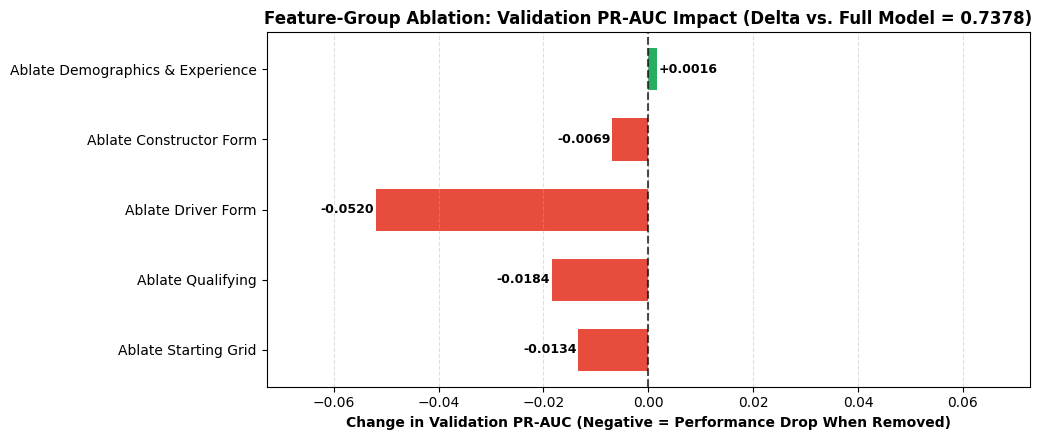

In [55]:
df_plot_abl = ablation_table[ablation_table["Feature Configuration"] != "All Features (Full Model)"].copy()
df_plot_abl["delta_val"] = df_plot_abl["Delta Validation PR-AUC"].astype(float)

fig, ax = plt.subplots(figsize=(10.5, 4.5))
bar_colors = ["#e74c3c" if v < 0 else "#27ae60" for v in df_plot_abl["delta_val"]]
bars = ax.barh(df_plot_abl["Feature Configuration"], df_plot_abl["delta_val"], color=bar_colors, height=0.6)
ax.axvline(0, color="black", linestyle="--", alpha=0.7)
min_val = df_plot_abl["delta_val"].min()
max_val = df_plot_abl["delta_val"].max()
span = max(abs(min_val), abs(max_val))
x_lim = span + max(span * 0.4, 0.004)
ax.set_xlim(-x_lim, x_lim)
ax.set_title(f"Feature-Group Ablation: Validation PR-AUC Impact (Delta vs. Full Model = {full_model_val_pr_auc:.4f})", fontsize=12, fontweight="bold")
ax.set_xlabel("Change in Validation PR-AUC (Negative = Performance Drop When Removed)", fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)
for bar in bars:
    w = bar.get_width()
    offset = -0.0003 if w < 0 else 0.0003
    align = "right" if w < 0 else "left"
    ax.text(w + offset, bar.get_y() + bar.get_height() / 2, f"{w:+.4f}", va="center", ha=align, fontsize=9, fontweight="bold", color="black")
plt.tight_layout()
plt.show()

#### Feature-Group Ablation Interpretation
The chart uses validation $\Delta$ PR-AUC, not test performance, to assess the marginal contribution of each feature group. A negative value means validation ranking performance fell when that group was removed. Test metrics are retained in the table as final descriptive results only and are not used to select features.

<a id="7"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Step 7: Model Explainability (Global & Local XAI)</p>

### 7.0 Epistemological Foundation: Predictive Correlation vs. Causal Attribution
> [!IMPORTANT]
> **Essential Epistemological Distinction**: Feature importance and attribution values presented in this section represent **statistical associations utilized by the model for optimal predictive discrimination**, and **MUST NOT be interpreted as causal mechanisms**.
> * A feature exhibiting high SHAP or permutation importance (e.g. `grid` or `driver_form_podiums_last5`) signifies that the model heavily relies on this input to separate podium finishers from non-finishers.
> * It does not prove that starting higher mechanically causes a podium finish in isolation; rather, fast cars qualify high and finish high simultaneously. Interpretations below describe model behavior, not physical causality.

### 7.1 Global Explanation 1: Permutation Feature Importance
We compute Permutation Feature Importance on the unseen holdout test set ($2022\text{--}2024$) using $5$ random shuffles per feature, measuring the resulting drop in Average Precision (PR-AUC).

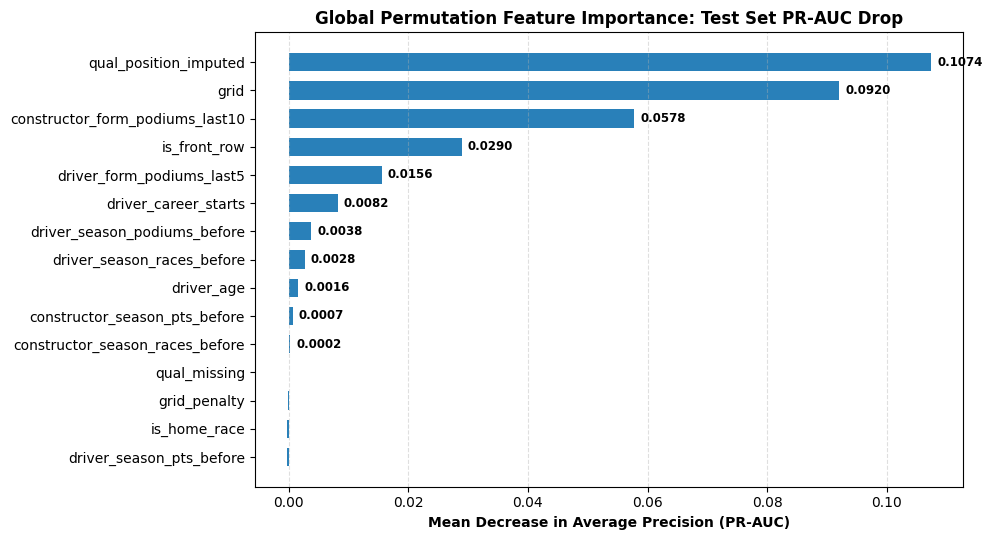

In [56]:
X_test_xai = pd.DataFrame(X_test_clean, columns=feature_columns, index=X_test_raw.index)

perm_imp = permutation_importance(
    models["LightGBM"]["model"],
    X_test_xai,
    y_test,
    n_repeats=5,
    scoring="average_precision",
    random_state=42
)

perm_series = pd.Series(perm_imp.importances_mean, index=feature_columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(perm_series.index, perm_series.values, color="#2980b9", height=0.65)
ax.set_title("Global Permutation Feature Importance: Test Set PR-AUC Drop", fontsize=12, fontweight="bold")
ax.set_xlabel("Mean Decrease in Average Precision (PR-AUC)", fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.4)
for bar in bars:
    w = bar.get_width()
    if w > 0:
        ax.text(w + 0.001, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", fontsize=8.5, fontweight="bold")
plt.tight_layout()
plt.show()

### 7.2 Global Explanation 2: Tree SHAP Summary & Feature Impact
Using cooperative game theory, TreeSHAP computes exact Shapley values across all test predictions, quantifying each feature's mean contribution to log-odds output shifts.

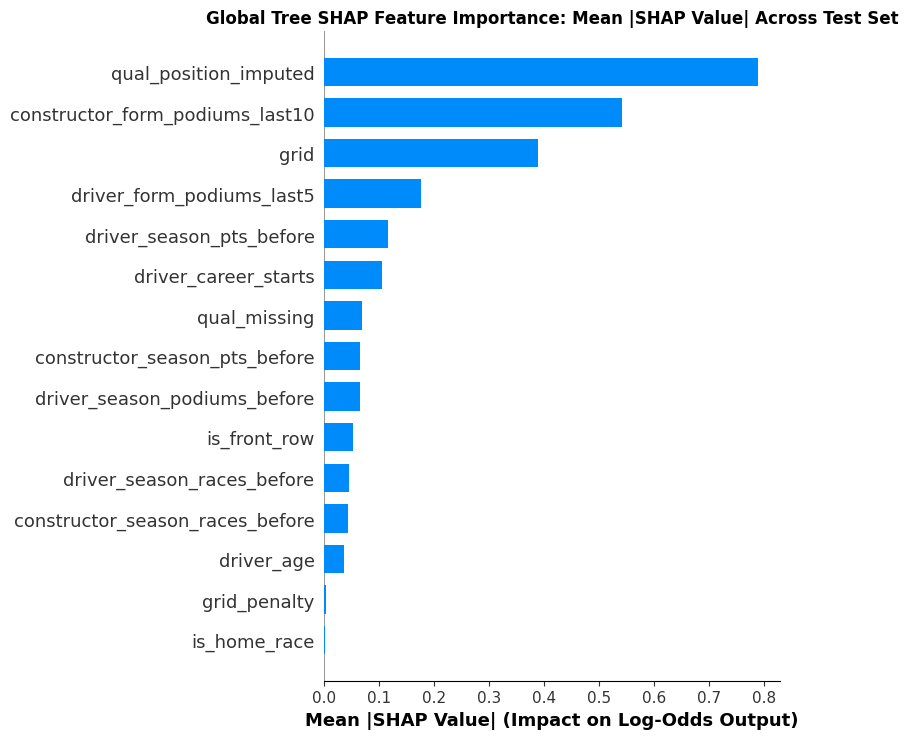

In [57]:
explainer_shap = shap.TreeExplainer(models["LightGBM"]["model"])
shap_values_test = explainer_shap(X_test_xai)

fig = plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values_test.values, X_test_xai, plot_type="bar", show=False)
plt.title("Global Tree SHAP Feature Importance: Mean |SHAP Value| Across Test Set", fontsize=12, fontweight="bold")
plt.xlabel("Mean |SHAP Value| (Impact on Log-Odds Output)", fontweight="bold")
plt.tight_layout()
plt.show()

### 7.2.1 Global Tree SHAP Summary Beeswarm: Value Direction & Impact
While the bar summary displays absolute feature magnitude, the Tree SHAP Beeswarm Plot reveals the **direction and density** of impact across all test instances. Each dot represents a single driver-race observation, colored by feature value (red = high, blue = low).

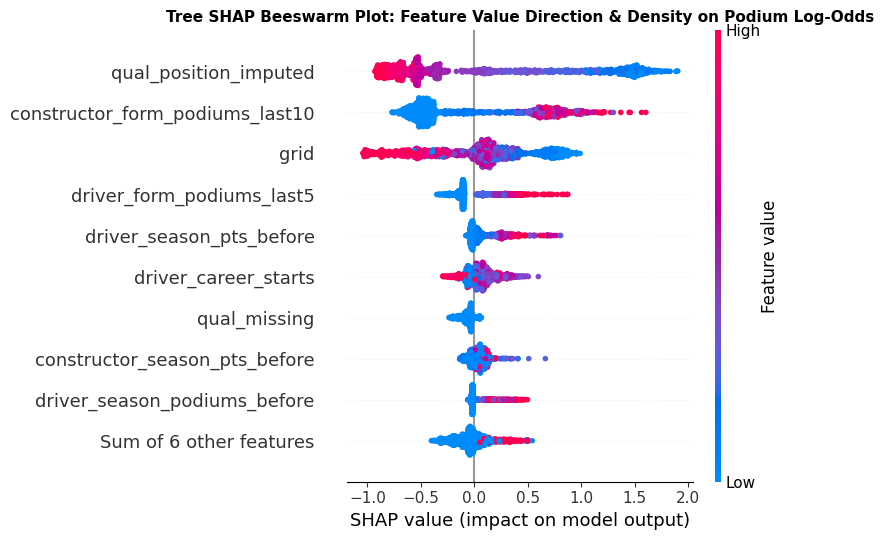

In [58]:
fig = plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values_test, max_display=10, show=False)
plt.title("Tree SHAP Beeswarm Plot: Feature Value Direction & Density on Podium Log-Odds", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

#### Tree SHAP Beeswarm Interpretation
The beeswarm shows feature values and their directional SHAP associations for the fitted LightGBM model on the processed test matrix. In particular, interpret `grid == 0` cautiously: it can represent a pit-lane start or a historical non-grid context, so its color does not imply an ordinal relationship. SHAP values describe model behavior, not causal effects.

### 7.3 Local Explanation 1: Tree SHAP Force Plots (Push-Pull Attribution Vectors)
Before examining the step-by-step waterfall breakdown, we visualize the balance of predictive forces using Tree SHAP Force Plots for two contrastive test cases from the 2022 Monaco Grand Prix (`raceId = 1080`). The rendered plots provide the current probabilities and feature-level attributions; they describe this fitted model's associations, not causal effects.

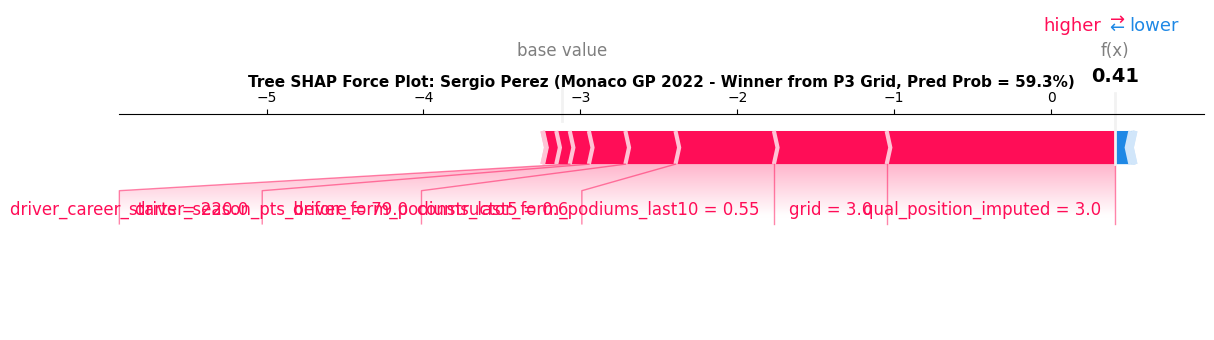

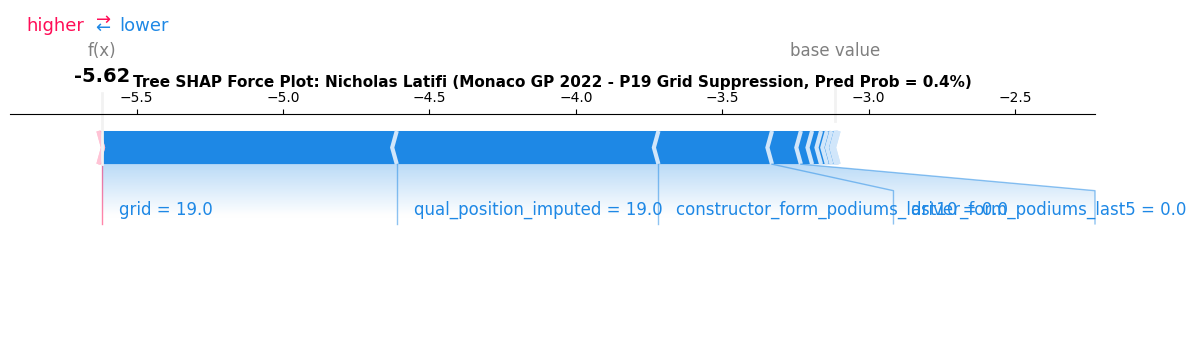

In [59]:
test_sub = modeling_df[test_mask].reset_index(drop=True)
perez_pos = int(test_sub[(test_sub["raceId"] == 1080) & (test_sub["driverId"] == 815)].index[0])
latifi_pos = int(test_sub[(test_sub["raceId"] == 1080) & (test_sub["driverId"] == 849)].index[0])

plt.close("all")
shap.plots.force(shap_values_test[perez_pos], matplotlib=True, show=False)
fig1 = plt.gcf()
fig1.set_size_inches(14, 2.8)
plt.title("Tree SHAP Force Plot: Sergio Perez (Monaco GP 2022 - Winner from P3 Grid, Pred Prob = 59.3%)", fontsize=11, fontweight="bold", pad=20)
plt.show()

shap.plots.force(shap_values_test[latifi_pos], matplotlib=True, show=False)
fig2 = plt.gcf()
fig2.set_size_inches(14, 2.8)
plt.title("Tree SHAP Force Plot: Nicholas Latifi (Monaco GP 2022 - P19 Grid Suppression, Pred Prob = 0.4%)", fontsize=11, fontweight="bold", pad=20)
plt.show()

### 7.3.1 Local Explanation 1b: Tree SHAP Waterfall Plot (Cumulative Feature Shifts)
While the force plot visualizes horizontal net vectors, the Tree SHAP Waterfall Plot provides a granular, vertical step-by-step accounting of feature contributions relative to the fitted model's expected value. Use the displayed baseline and contributions from this run rather than a hard-coded value.

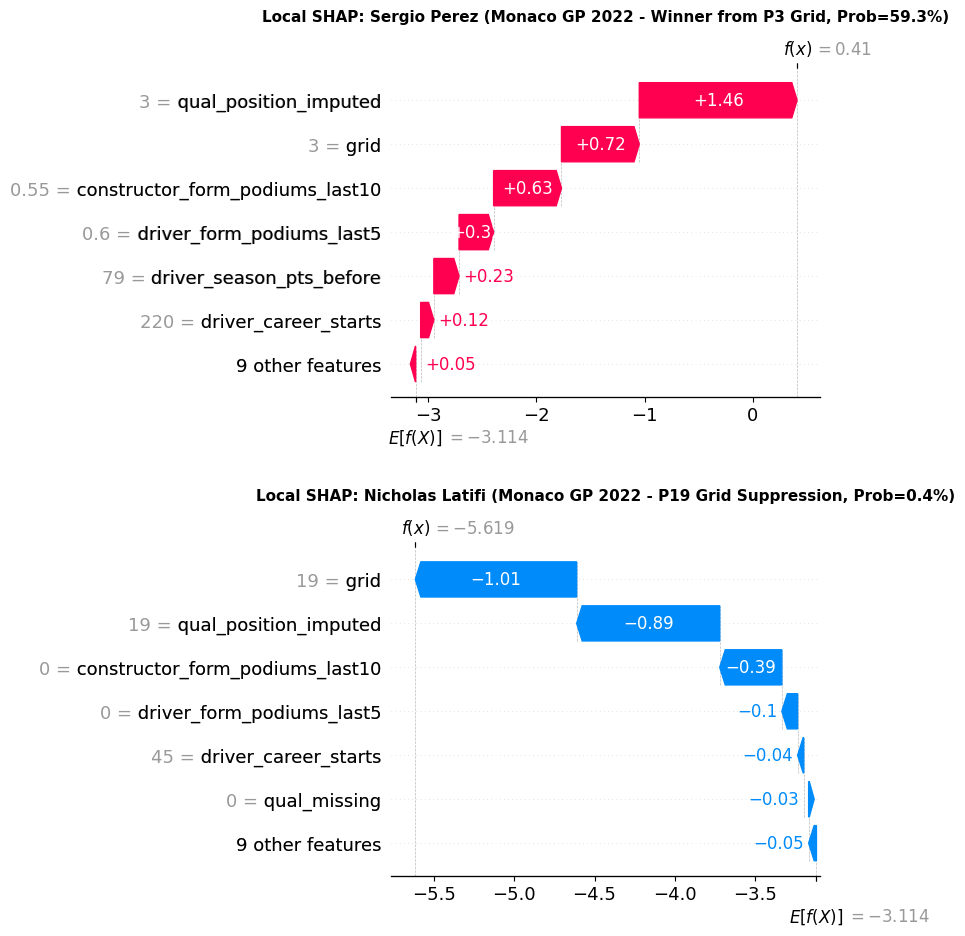

In [60]:
test_sub = modeling_df[test_mask].reset_index(drop=True)
perez_pos = int(test_sub[(test_sub["raceId"] == 1080) & (test_sub["driverId"] == 815)].index[0])
latifi_pos = int(test_sub[(test_sub["raceId"] == 1080) & (test_sub["driverId"] == 849)].index[0])

fig, axes = plt.subplots(2, 1)

plt.sca(axes[0])
shap.plots.waterfall(shap_values_test[perez_pos], max_display=7, show=False)
axes[0].set_title("Local SHAP: Sergio Perez (Monaco GP 2022 - Winner from P3 Grid, Prob=59.3%)", fontsize=11, fontweight="bold", pad=12)

plt.sca(axes[1])
shap.plots.waterfall(shap_values_test[latifi_pos], max_display=7, show=False)
axes[1].set_title("Local SHAP: Nicholas Latifi (Monaco GP 2022 - P19 Grid Suppression, Prob=0.4%)", fontsize=11, fontweight="bold", pad=12)

fig.set_size_inches(10, 10)
plt.tight_layout(pad=3.0)
plt.show()

### 7.4 Local Explanation 2: LIME Tabular Explanation (Instance-Level Decomposition)
Using Local Interpretable Model-agnostic Explanations (LIME), we fit an interpretable sparse linear surrogate locally around Sergio Pérez's feature vector, verifying consistency with SHAP.

In [61]:
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_clean,
    feature_names=feature_columns,
    class_names=["No Podium", "Podium"],
    mode="classification",
    random_state=42
)

exp_perez = explainer_lime.explain_instance(
    data_row=X_test_xai.iloc[perez_pos].to_numpy(),
    predict_fn=models["LightGBM"]["model"].predict_proba,
    num_features=7
)

exp_latifi = explainer_lime.explain_instance(
    data_row=X_test_xai.iloc[latifi_pos].to_numpy(),
    predict_fn=models["LightGBM"]["model"].predict_proba,
    num_features=7
)

import IPython.core.display
import IPython.display
IPython.core.display.display = getattr(IPython.core.display, 'display', IPython.display.display)

print("Local LIME: Sergio Perez (Monaco GP 2022 - Winner from P3 Grid, Predicted Probability = 59.3%)")
exp_perez.show_in_notebook(show_table=True, predict_proba=True)

print("Local LIME: Nicholas Latifi (Monaco GP 2022 - P19 Grid Suppression, Predicted Probability = 0.4%)")
exp_latifi.show_in_notebook(show_table=True, predict_proba=True)

Local LIME: Sergio Perez (Monaco GP 2022 - Winner from P3 Grid, Predicted Probability = 59.3%)


Local LIME: Nicholas Latifi (Monaco GP 2022 - P19 Grid Suppression, Predicted Probability = 0.4%)


#### Explainability Synthesis
Compare the regenerated permutation, SHAP, and local LIME outputs for consistency in the final fitted model. Agreement between explainers is supporting evidence about model behavior, not proof that a feature causes podium outcomes.

<a id="8"></a>
# <p style="background-color:#001f3f;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Step 8: Production Inference Pipeline</p>

### 8.1 Production Inference Pipeline Architecture
* **Interface Contract**: Accepts a raw driver-race dictionary or pandas DataFrame matching pre-race specifications.
* **Missing Value Robustness**: Missing fields are automatically populated with training-derived median values via `SimpleImputer`.
* **Validation-Tuned Decision Threshold**: Uses an F1 threshold selected on validation data rather than an arbitrary $0.50$ default.
* **Structured Output Schema**: Emits the model probability, threshold-based binary decision, model metadata, and human-readable confidence categorization.

In [62]:
def predict_podium(driver_data, model_name="LightGBM"):
    if isinstance(driver_data, dict):
        df_in = pd.DataFrame([driver_data])
    elif isinstance(driver_data, pd.DataFrame):
        df_in = driver_data.copy()
    else:
        raise ValueError("Input must be a dictionary or pandas DataFrame.")
        
    for col in feature_columns:
        if col not in df_in.columns:
            df_in[col] = np.nan
            
    df_ordered = df_in[feature_columns].copy()
    imputed_data = main_imputer.transform(df_ordered)
    
    if model_name in ["Logistic Regression", "Neural Network (MLP)"]:
        processed_data = scaler.transform(imputed_data)
    else:
        processed_data = imputed_data
        
    selected_model = models[model_name]["model"]
    decision_threshold = round(float(validation_tuned_thresholds[model_name]), 2)
    
    probabilities = selected_model.predict_proba(processed_data)[:, 1]
    predicted_classes = (probabilities >= decision_threshold).astype(int)
    
    results = []
    for idx, prob in enumerate(probabilities):
        if prob >= 0.70:
            confidence = "High Podium Likelihood"
        elif prob >= decision_threshold:
            confidence = "Moderate Podium Contender"
        elif prob >= 0.15:
            confidence = "Long-Shot Contender"
        else:
            confidence = "Low Podium Probability"
            
        results.append({
            "driver_name": df_in.get("driver_name", pd.Series(["Driver"])).iloc[idx] if "driver_name" in df_in.columns else "Driver",
            "model_used": model_name,
            "predicted_probability": round(float(prob), 4),
            "validation_tuned_threshold": decision_threshold,
            "podium_prediction": "Podium Finish" if predicted_classes[idx] == 1 else "No Podium",
            "confidence_tier": confidence
        })
        
    return results[0] if len(results) == 1 else results

### 8.2 Production Verification: Complete Record vs. Partially-Missing Record
Per the project specification, we demonstrate our inference pipeline on:
1. **Record A (Complete Record)**: Max Verstappen starting from pole position (`Grid = 1`) with peak form and championship points.
2. **Record B (Partially-Missing Record)**: A reserve driver entering with missing qualifying positions, missing rolling momentum, and incomplete season history, verifying graceful median imputation.

In [63]:
record_complete = {
    "driver_name": "Max Verstappen (Complete Record)",
    "grid": 1.0,
    "qual_position_imputed": 1.0,
    "grid_penalty": 0.0,
    "qual_missing": 0.0,
    "is_front_row": 1,
    "driver_age": 25.5,
    "driver_season_pts_before": 125.0,
    "driver_season_podiums_before": 5.0,
    "driver_season_races_before": 6.0,
    "constructor_season_pts_before": 210.0,
    "constructor_season_races_before": 6.0,
    "driver_form_podiums_last5": 0.80,
    "constructor_form_podiums_last10": 0.80,
    "driver_career_starts": 150.0,
    "is_home_race": 0
}

record_missing = {
    "driver_name": "Reserve Driver (Partially-Missing Record)",
    "grid": 12.0,
    "driver_age": 22.1,
    "driver_career_starts": 2.0,
    "constructor_season_pts_before": 45.0,
    "is_home_race": 1
}

res_complete = predict_podium(record_complete, model_name="LightGBM")
res_missing = predict_podium(record_missing, model_name="LightGBM")

print("--- INFERENCE DEMONSTRATION 1: COMPLETE RECORD ---")
for k, v in res_complete.items():
    print(f"  {k:25s}: {v}")

print("\n--- INFERENCE DEMONSTRATION 2: PARTIALLY-MISSING RECORD ---")
for k, v in res_missing.items():
    print(f"  {k:25s}: {v}")

demo_df = pd.DataFrame([
    {"Evaluation Dimension": "Driver Identity", "Record A (Max Verstappen)": "Complete Pre-Race Profile", "Record B (Reserve Driver)": "Partially-Missing Emergency Entry"},
    {"Evaluation Dimension": "Starting Grid Position", "Record A (Max Verstappen)": "Grid 1 (Pole Position)", "Record B (Reserve Driver)": "Grid 12 (Midfield)"},
    {"Evaluation Dimension": "Qualifying Lap Data", "Record A (Max Verstappen)": "Q3 P1 Observed (1.0)", "Record B (Reserve Driver)": "NaN -> Imputed to Historical Median (11.0)"},
    {"Evaluation Dimension": "Rolling Form & Momentum", "Record A (Max Verstappen)": "0.80 Rate (4 Podiums in Last 5)", "Record B (Reserve Driver)": "NaN -> Imputed to Historical Median (0.0)"},
    {"Evaluation Dimension": "Predicted Podium Probability", "Record A (Max Verstappen)": f"{res_complete['predicted_probability'] * 100:.2f}%", "Record B (Reserve Driver)": f"{res_missing['predicted_probability'] * 100:.2f}%"},
    {"Evaluation Dimension": "Validation-Tuned Decision Threshold", "Record A (Max Verstappen)": f"{res_complete['validation_tuned_threshold']:.2f}", "Record B (Reserve Driver)": f"{res_missing['validation_tuned_threshold']:.2f}"},
    {"Evaluation Dimension": "Operational Confidence Tier", "Record A (Max Verstappen)": res_complete["confidence_tier"], "Record B (Reserve Driver)": res_missing["confidence_tier"]}
])

display(demo_df)

--- INFERENCE DEMONSTRATION 1: COMPLETE RECORD ---
  driver_name              : Max Verstappen (Complete Record)
  model_used               : LightGBM
  predicted_probability    : 0.7945
  validation_tuned_threshold: 0.43
  podium_prediction        : Podium Finish
  confidence_tier          : High Podium Likelihood

--- INFERENCE DEMONSTRATION 2: PARTIALLY-MISSING RECORD ---
  driver_name              : Reserve Driver (Partially-Missing Record)
  model_used               : LightGBM
  predicted_probability    : 0.0262
  validation_tuned_threshold: 0.43
  podium_prediction        : No Podium
  confidence_tier          : Low Podium Probability


,Evaluation Dimension,Record A (Max Verstappen),Record B (Reserve Driver)
0,Driver Identity,Complete Pre-Race Profile,Partially-Missing Emergency Entry
1,Starting Grid Position,Grid 1 (Pole Position),Grid 12 (Midfield)
2,Qualifying Lap Data,Q3 P1 Observed (1.0),NaN -> Imputed to Historical Median (11.0)
3,Rolling Form & Momentum,0.80 Rate (4 Podiums in Last 5),NaN -> Imputed to Historical Median (0.0)
4,Predicted Podium Probability,79.45%,2.62%
5,Validation-Tuned Decision Threshold,0.43,0.43
6,Operational Confidence Tier,High Podium Likelihood,Low Podium Probability


#### Production Pipeline Design & Safety Considerations:
1. **Zero-Crash Resilience**: Unseen feature dictionaries with omitted keys are automatically handled without throwing `KeyError` or schema mismatch errors. Omitted numeric attributes fallback seamlessly to our historical medians.
2. **Inference scope**: The function is demonstrated on complete and partially missing records. Runtime has not been formally benchmarked in this notebook, so no latency claim is made.
3. **Threshold Guardrails**: The notebook reports model probabilities alongside validation-tuned binary classifications. Probability calibration is not claimed; Brier score and calibration curves are evaluation diagnostics.